# Dataversity survey

* Survey sample: This was an opt-in industry survey, with self-selected participants drawn from the DATAVERSITY and Aristotle Metadata mailing lists. To expand reach, the link to the survey was shared with LinkedIn groups and data mailing surveys.
* Analysis included participants who did not provide an email were not excluded
* Respondents had a chance to discontinue the survey after page 1 (14 questions) and page two (18 questions)
* Respondents who did not respondent to a question were excluded from analysis.
* For pairwise analysis, a spearmans correlation was performed when comparing categorical data (AI vs each action question, etc…). Only pairs where the correlation was greater that 0.4 with a p-value less than 0.05 were kept for presentation.

    * For action questions (page 2) if a user selected response one “I don't do this as part of my current role” they were excluded from correlation analysis


In [1]:
from textwrap import fill

from scipy.stats import spearmanr

from mast_toolkit_notebooks.correlations import (
    compute_correlation_matrices,
    top_action_pairs,
)
from mast_toolkit_notebooks.plots import (
    choice_labels,
    plot_positive_metrics_by_category,
    plot_stacked_percent_barh,
    recoded_choice_labels,
    to_percent_exc_nan,
)
from mast_toolkit_notebooks.utils import (
    build_pairwise_data,
    prepare_survey,
    DONT_KNOW,
)
import pandas as pd

survey = prepare_survey(verbose=False)

responses = survey.responses
metadata = survey.metadata
analysis_df = survey.analysis_df
completed = survey.completed
rating_columns = survey.rating_columns
beliefs_columns = survey.beliefs_columns
action_columns = survey.action_columns
action_analysis_columns = survey.action_analysis_columns
self_assess_columns = survey.self_assess_columns
ai_outcome_columns = survey.ai_outcome_columns
recode_columns = survey.recode_columns

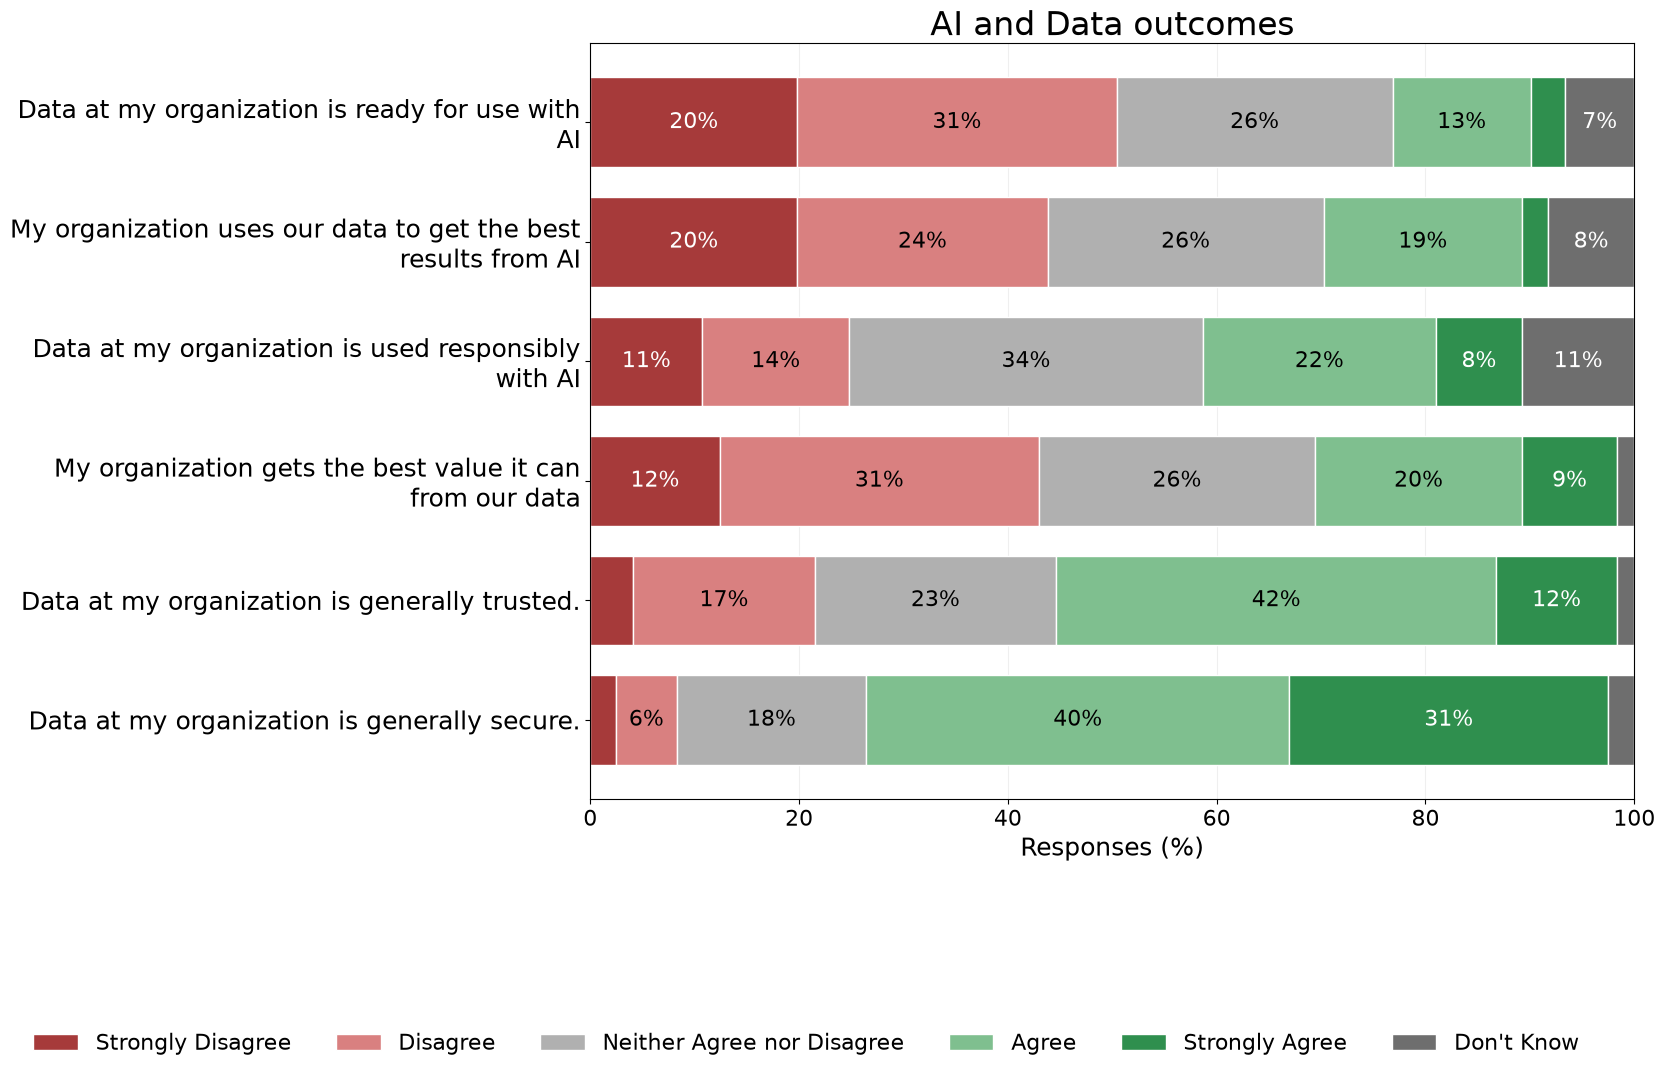

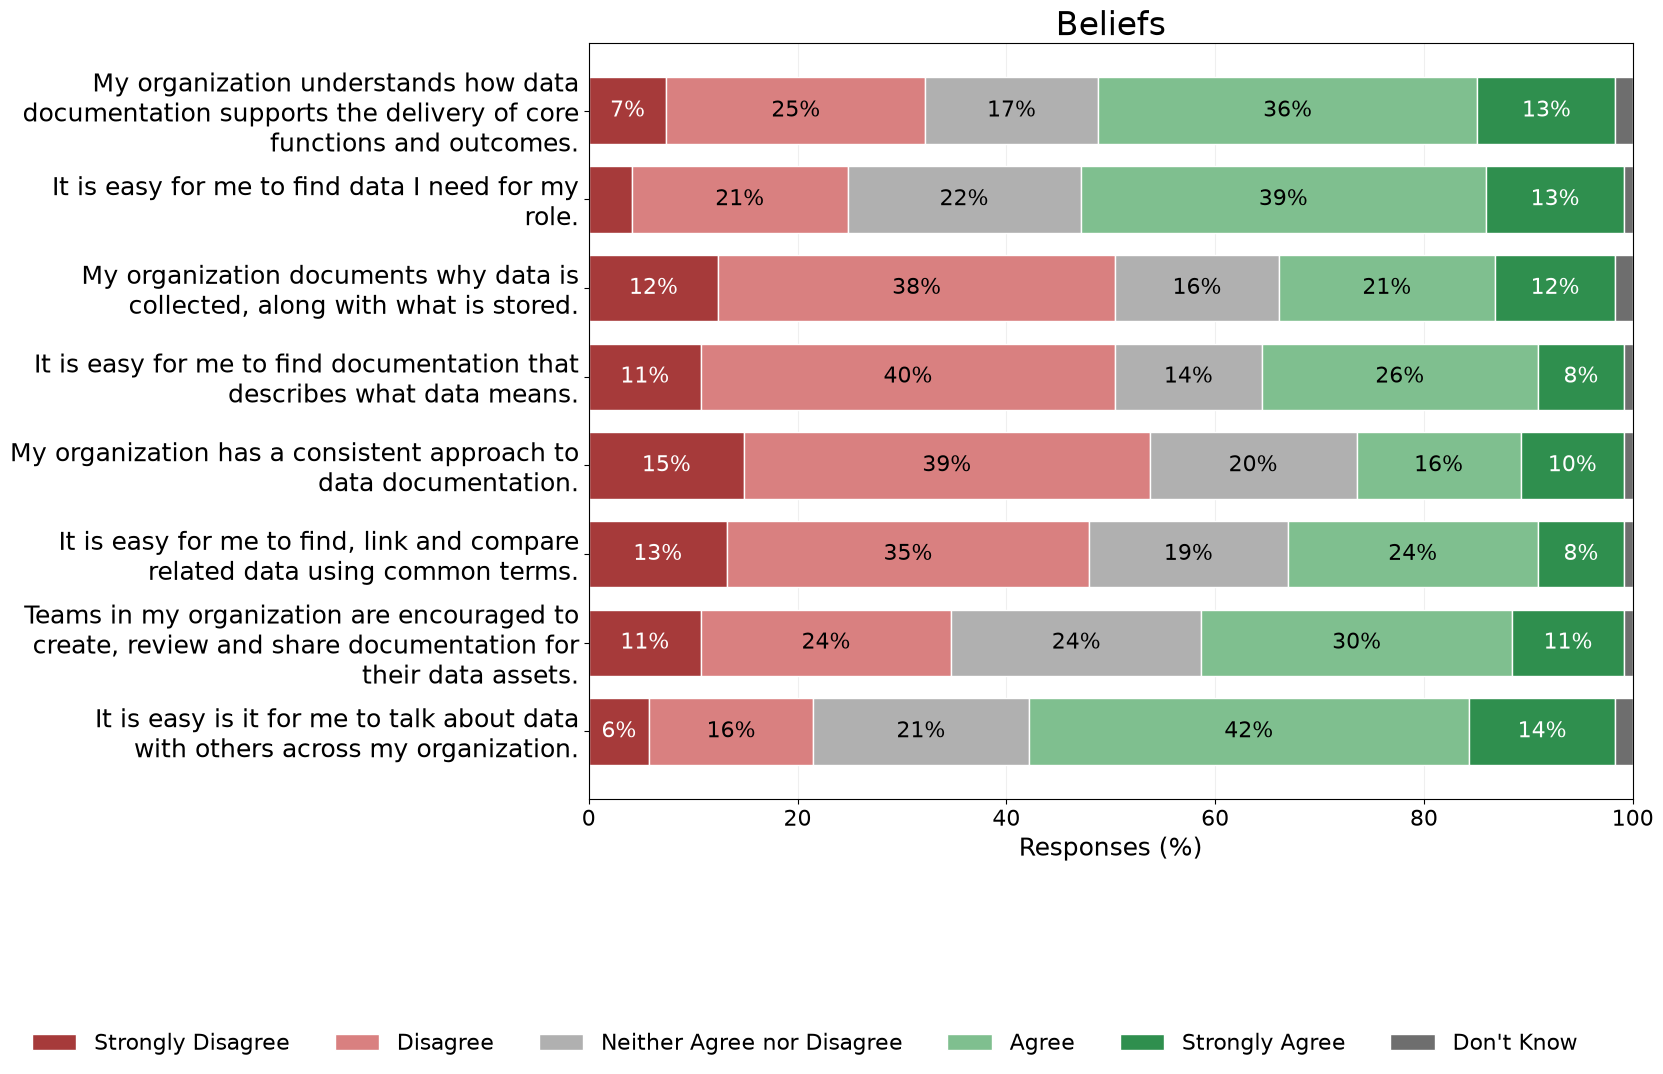

In [2]:
# Stack order: disagree (reds), neither and don't know (grays), agree (greens).
response_codes = [1, 2, 3, 4, 5, DONT_KNOW]
response_colors = {
    1: "#a63a3a",
    2: "#d98080",
    3: "#b0b0b0",
    4: "#7fbf8f",
    5: "#2f8f4e",
    DONT_KNOW: "#6e6e6e",
}

metadata_by_field = metadata.set_index("field_name")


def plot_response_percentages(columns, title):
    counts = pd.DataFrame(
        {
            column: completed[column].value_counts().reindex(response_codes, fill_value=0)
            for column in columns
        }
    ).T
    percentages = to_percent_exc_nan(counts)
    percentages.index = [
        fill(metadata_by_field.loc[column, "question text"], width=45)
        for column in columns
    ]
    plot_stacked_percent_barh(
        percentages, response_colors, choice_labels(metadata_by_field, columns[0]), title
    )


plot_response_percentages([*ai_outcome_columns, *self_assess_columns], "AI and Data outcomes")
plot_response_percentages(beliefs_columns, "Beliefs")

# Comparisons of strongest correlations for AI & actions.

The 3 strongest action and AI outcome pairs (adjusted Spearman |rho| > 0.4 and p < 0.05) are recalculated on every run. Each pair is shown with the original 1–5 ratings and the three-category recode. Action rating `1` ("I don't do this") and AI "don't know" responses are excluded; both graphs use the same respondents.

,action,outcome,rho,p_value
0,actions_endorse_1,ai_responsibility,0.483671,2.995277e-07
1,actions_endorse_2,ai_responsibility,0.463119,6.277243e-06
2,actions_leadership_2,ai_responsibility,0.407030,2.902479e-05


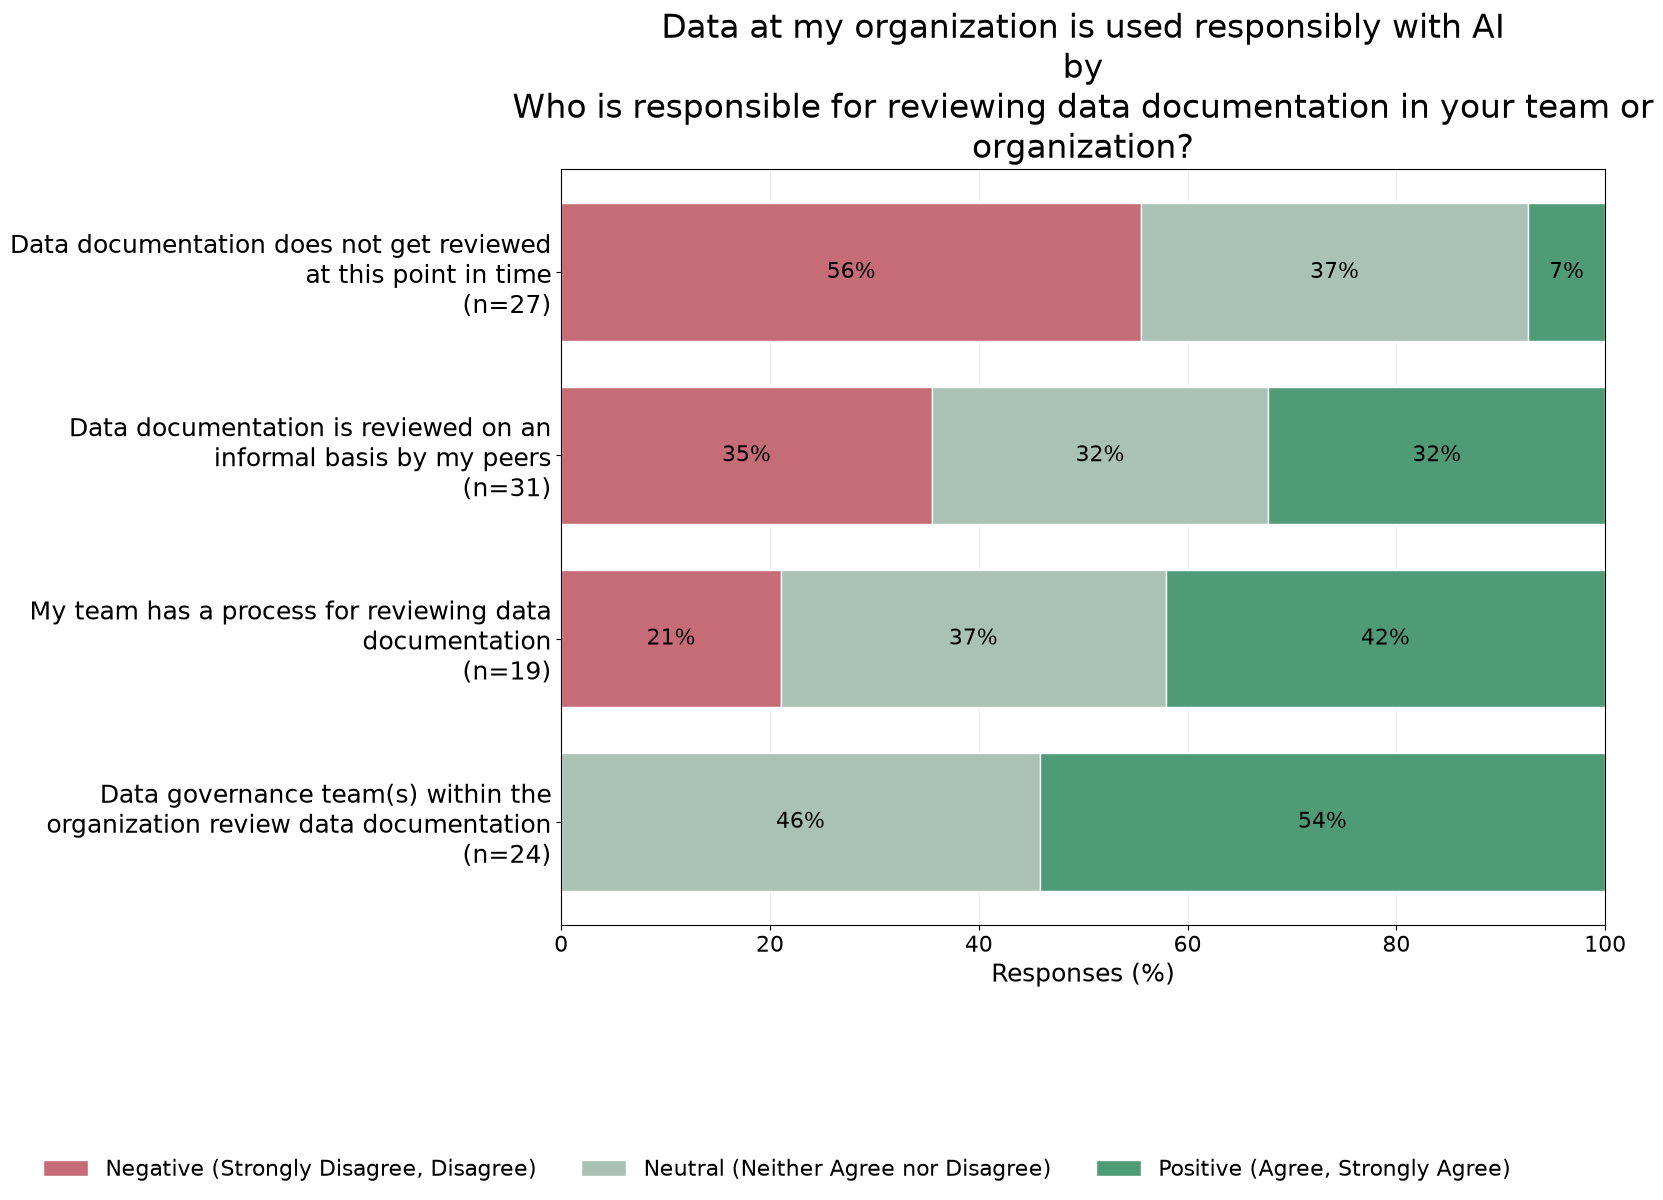

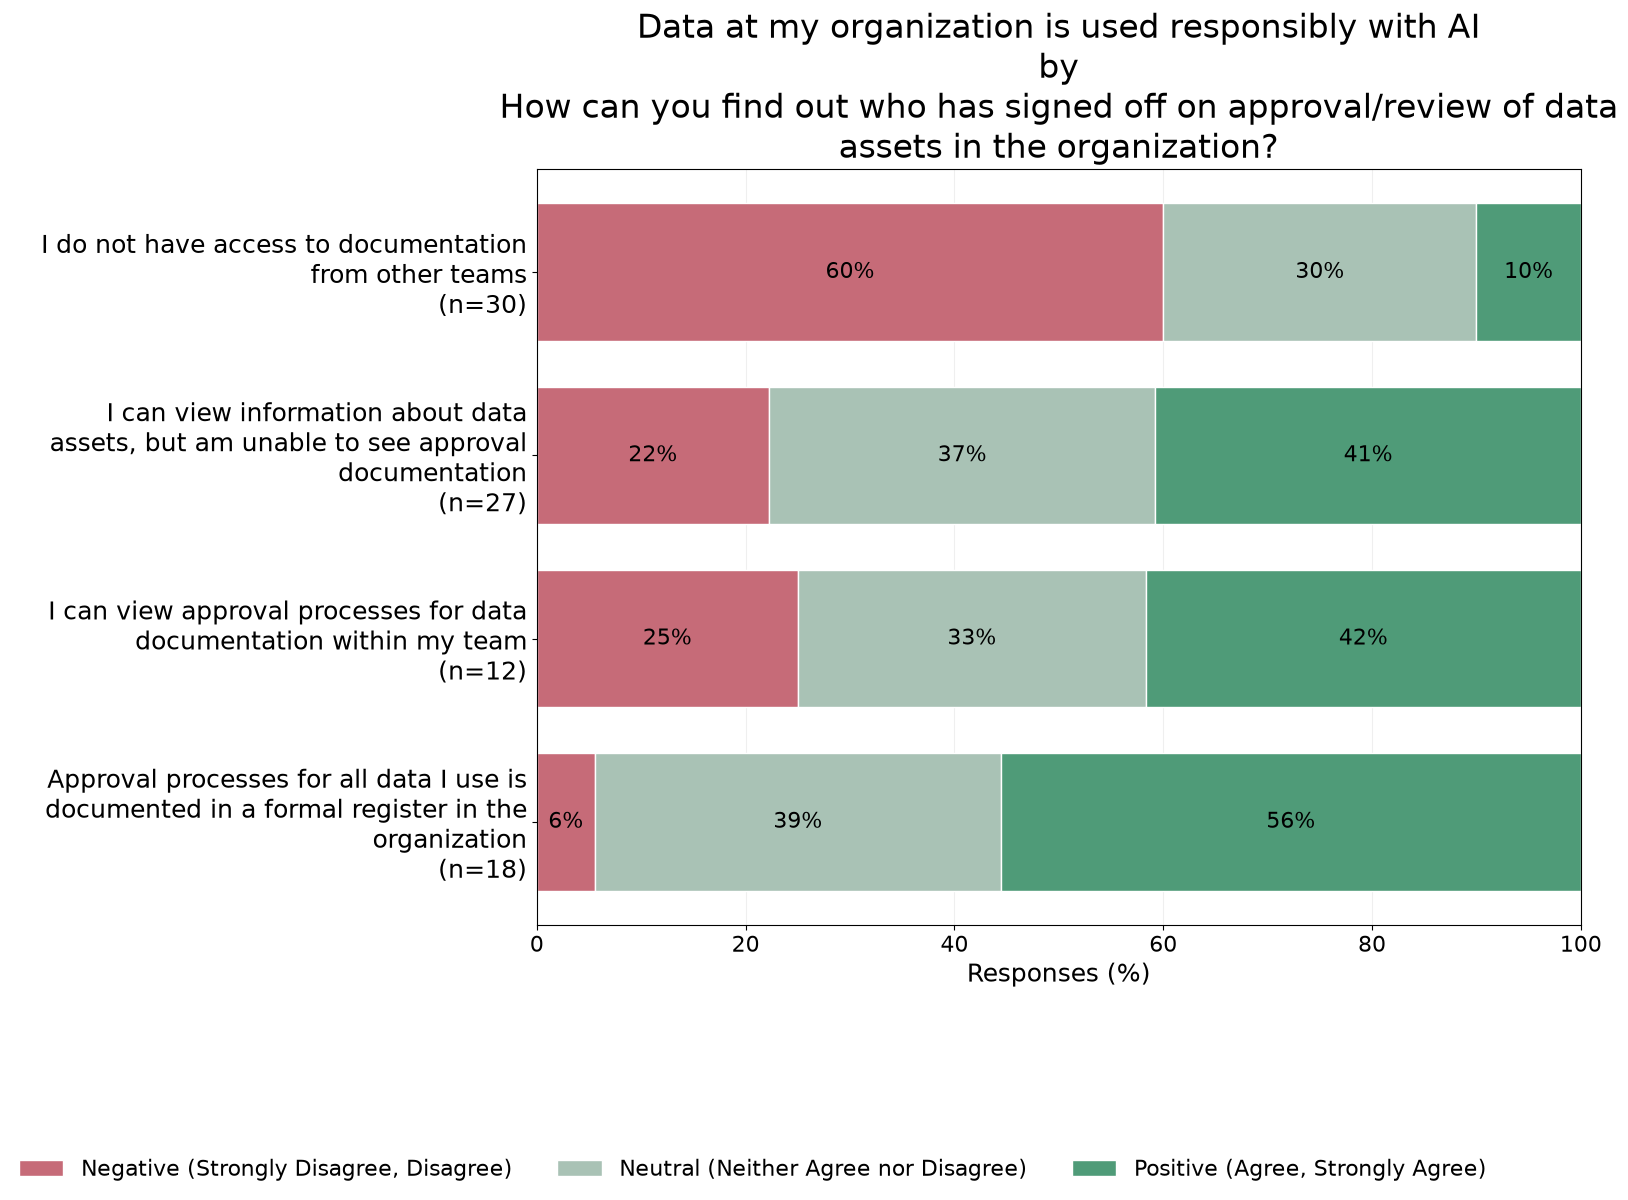

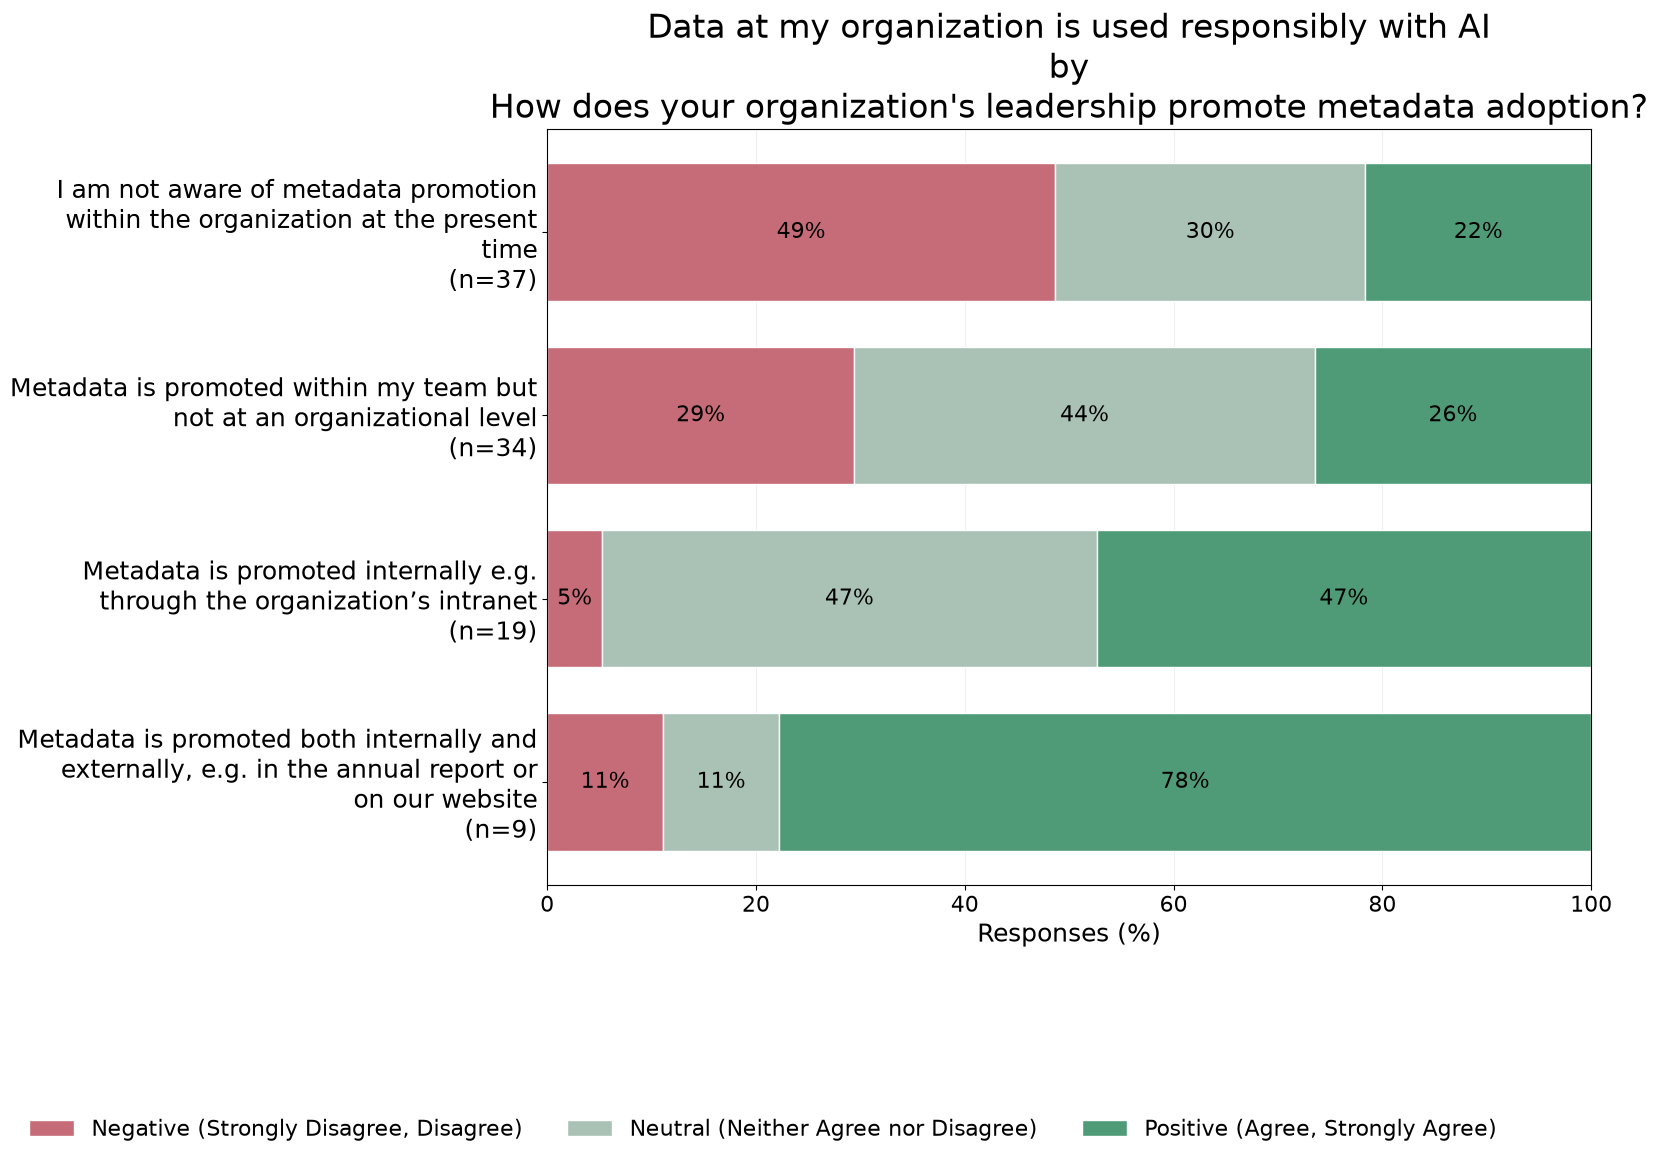

In [3]:
recoded_colors = {"negative": "#c66b78", "neutral": "#a9c2b5", "positive": "#4f9b78"}
action_ratings = [2, 3, 4, 5]


def plot_action_ai(action_column, ai_column, recoded, include_stats=True):
    action_analysis_column = action_analysis_columns[action_column]
    recoded_column = f"{ai_column}_recoded"
    recoded_score_column = f"{recoded_column}_score"
    if recoded:
        outcome_column, codes, colors, labels = (
            recoded_column, list(recoded_choice_labels), recoded_colors, recoded_choice_labels
        )
    else:
        outcome_column, codes, colors, labels = (
            ai_column, [1, 2, 3, 4, 5], response_colors, choice_labels(metadata_by_field, ai_column)
        )

    # Action rating 1 is masked and "don't know" has no recode score, so both are dropped.
    paired = completed[
        [action_analysis_column, ai_column, recoded_column, recoded_score_column]
    ].dropna()
    rho, p_value = spearmanr(paired[action_analysis_column], paired[recoded_score_column if recoded else ai_column])

    counts = pd.crosstab(paired[action_analysis_column], paired[outcome_column]).reindex(
        index=action_ratings, columns=codes, fill_value=0
    )
    percentages = to_percent_exc_nan(counts)
    action_labels = choice_labels(metadata_by_field, action_column)
    percentages.index = [
        f"{fill(action_labels[rating], width=40)}\n(n={int(counts.loc[rating].sum())})"
        for rating in action_ratings
    ]
    kind = "Grouped" if recoded else "Original"
    title = (
        fill(metadata_by_field.loc[ai_column, 'question text'], width=70) +
        "\n by \n" +
        fill(metadata_by_field.loc[action_column, 'question text'], width=70)
    )
    if include_stats:
        title += f"\n {kind} choices: rho={rho:.2f}, p={p_value:.3g}"
    plot_stacked_percent_barh(percentages, colors, labels, title)


matrices = compute_correlation_matrices(*build_pairwise_data(survey))
top_pairs = top_action_pairs(matrices, survey, "ai_responsibility")
display(top_pairs)
for pair in top_pairs.itertuples():
    # plot_action_ai(pair.action, pair.outcome, recoded=False)
    plot_action_ai(pair.action, pair.outcome, recoded=True, include_stats=False)

,action,outcome,rho,p_value
0,actions_endorse_1,ai_results,0.418056,0.000011


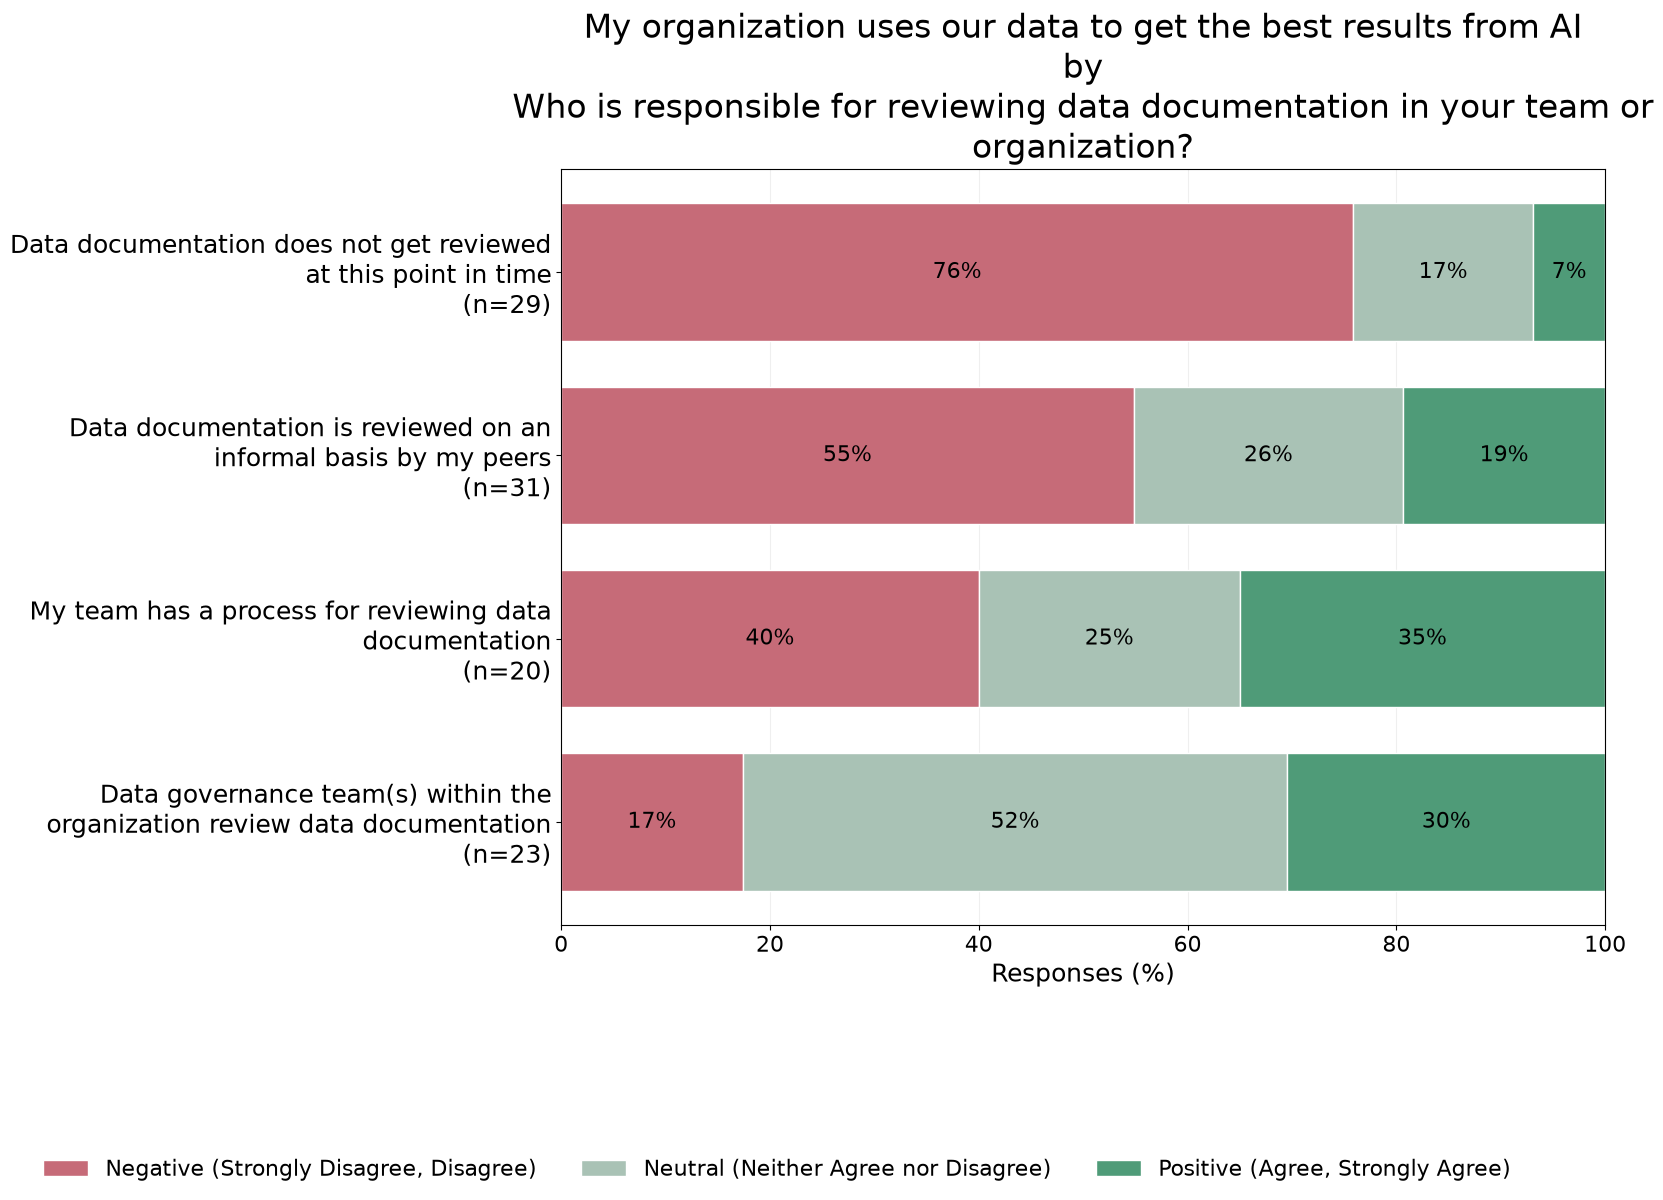

In [4]:
matrices = compute_correlation_matrices(*build_pairwise_data(survey))
top_pairs = top_action_pairs(matrices, survey, "ai_results")
display(top_pairs)
for pair in top_pairs.itertuples():
    # plot_action_ai(pair.action, pair.outcome, recoded=False)
    plot_action_ai(pair.action, pair.outcome, recoded=True, include_stats=False)

,action,outcome,rho,p_value
0,actions_endorse_1,ai_readiness,0.461312,8.286609e-07
1,actions_leadership_2,ai_readiness,0.422221,7.246294e-06
2,actions_endorse_2,ai_readiness,0.421261,3.206759e-05


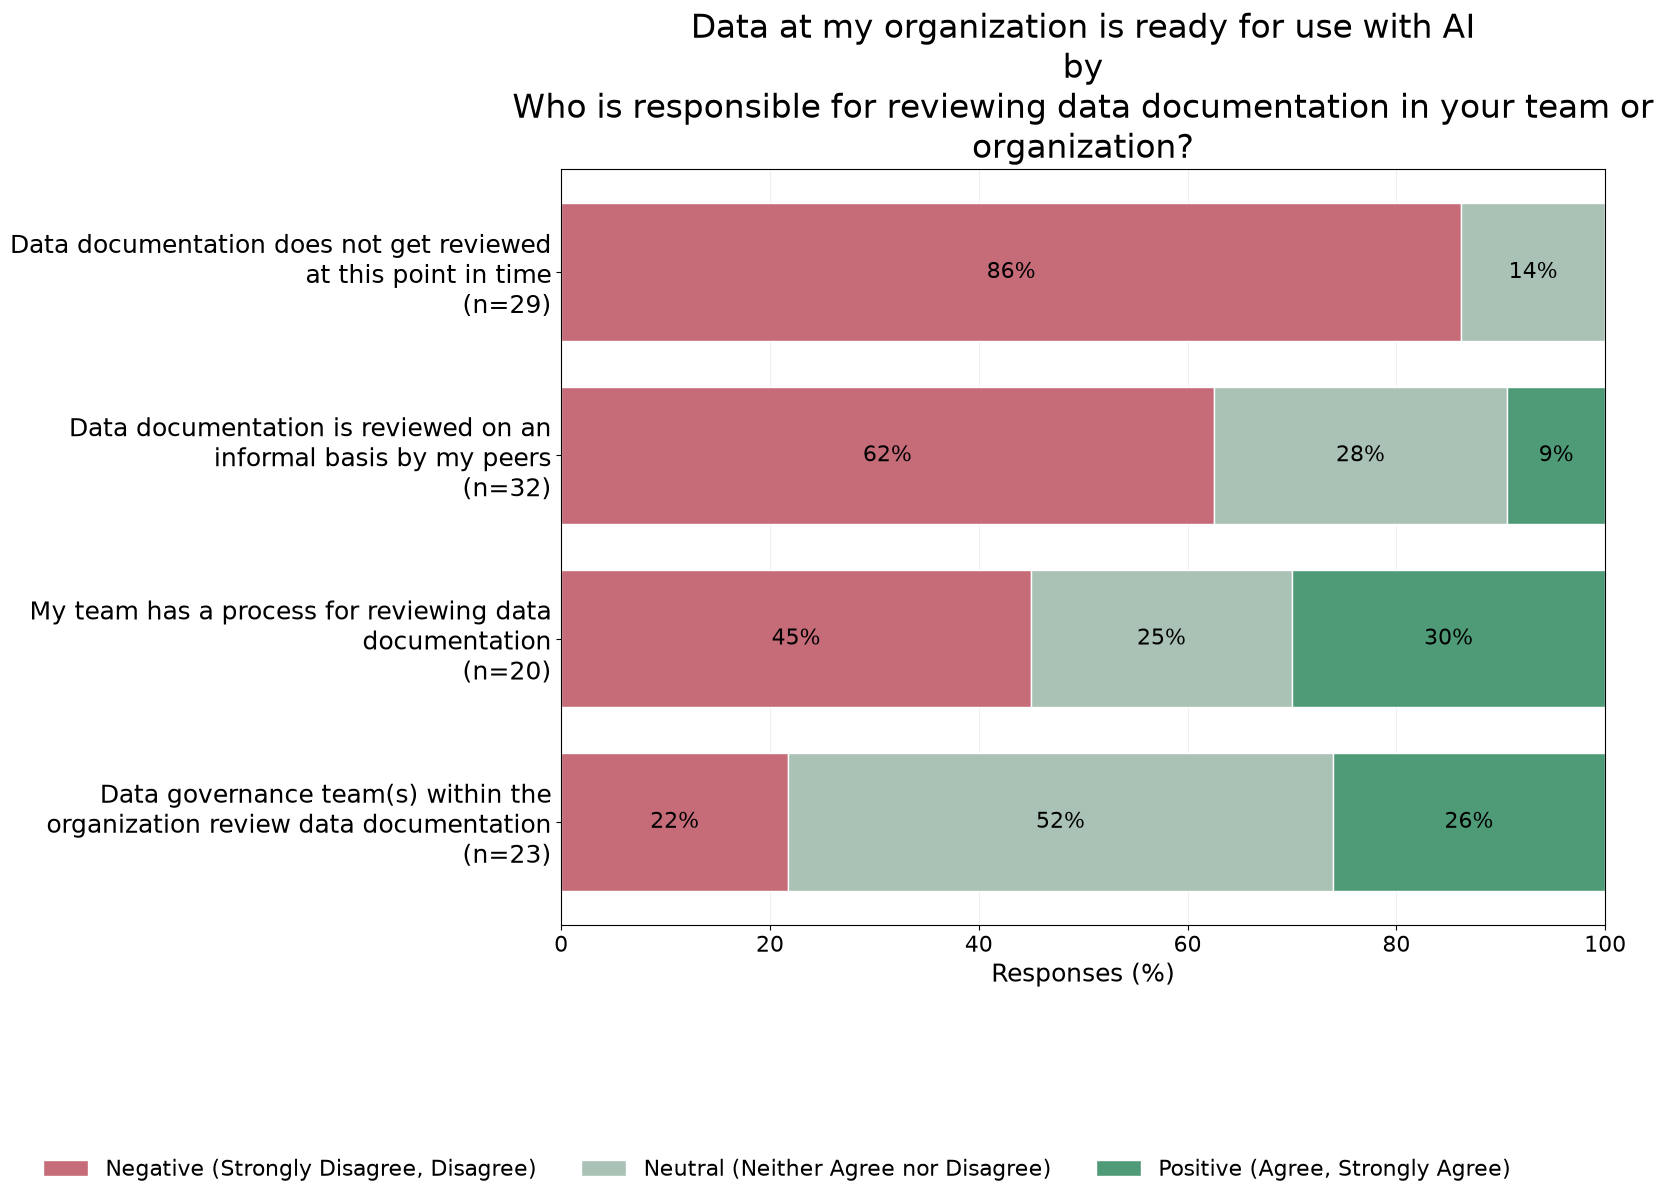

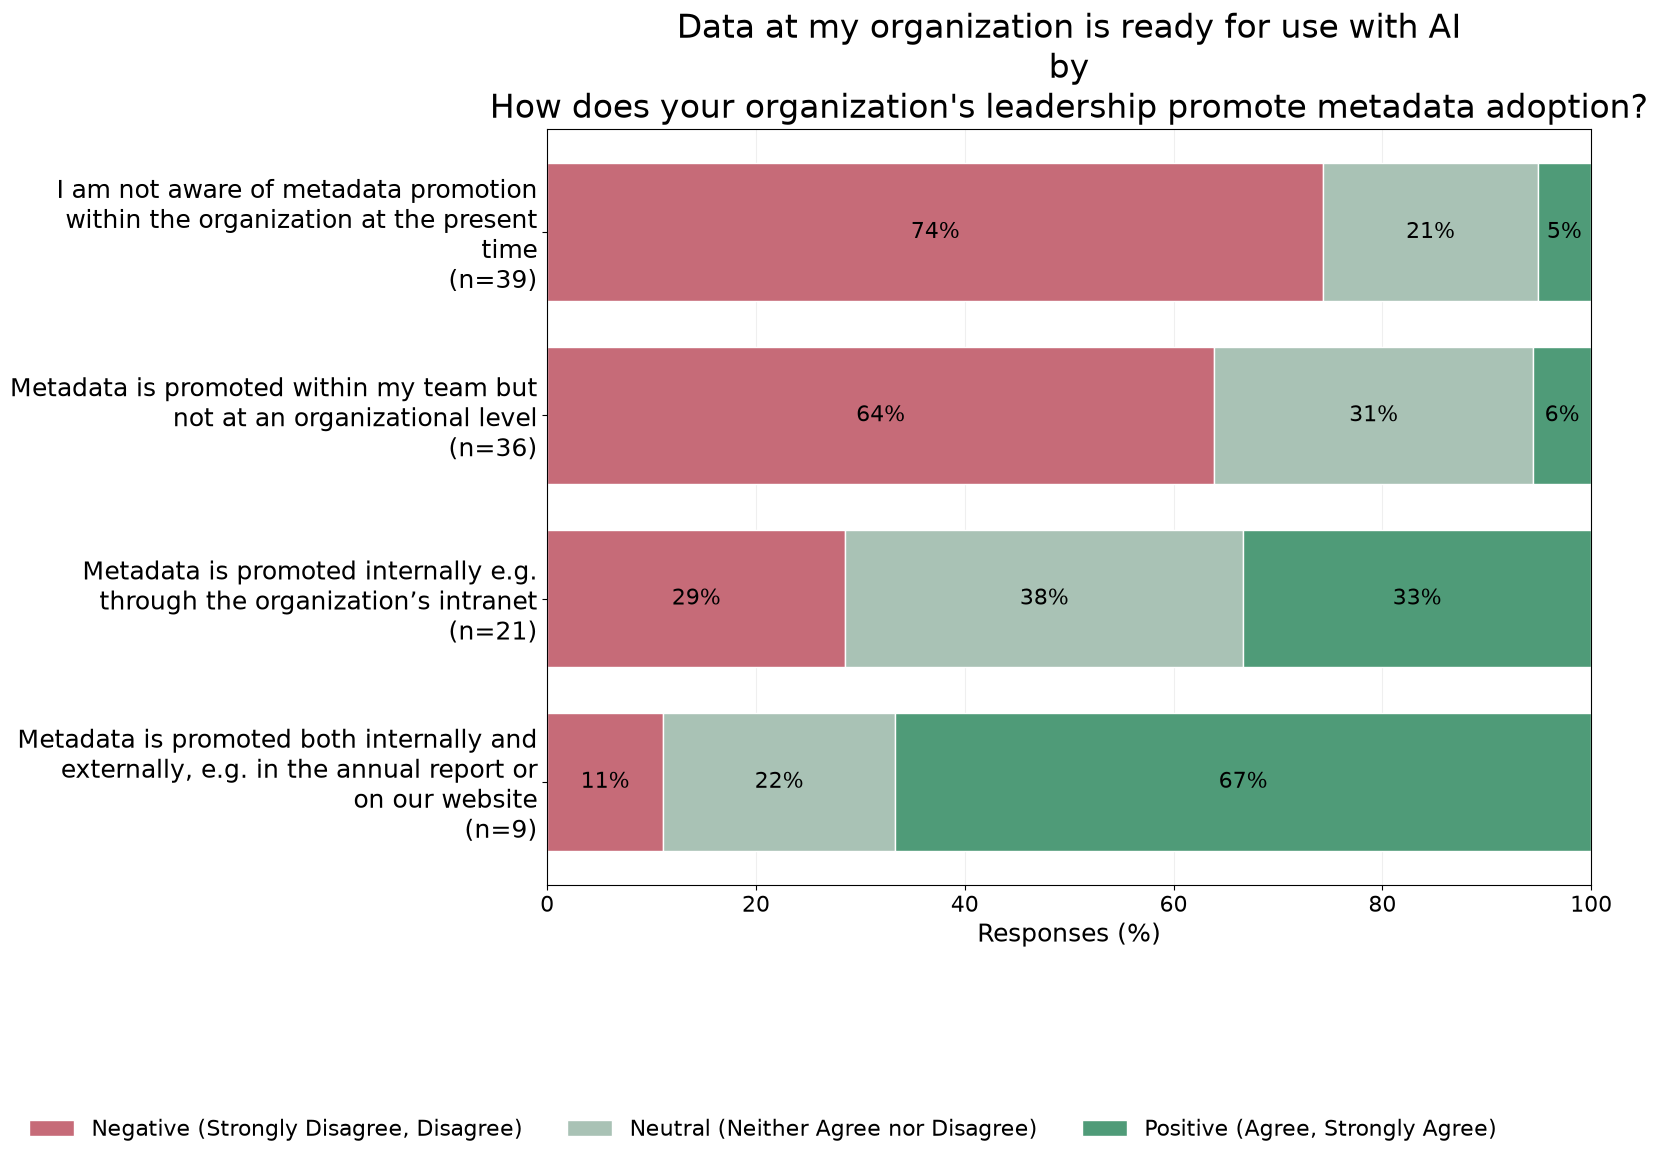

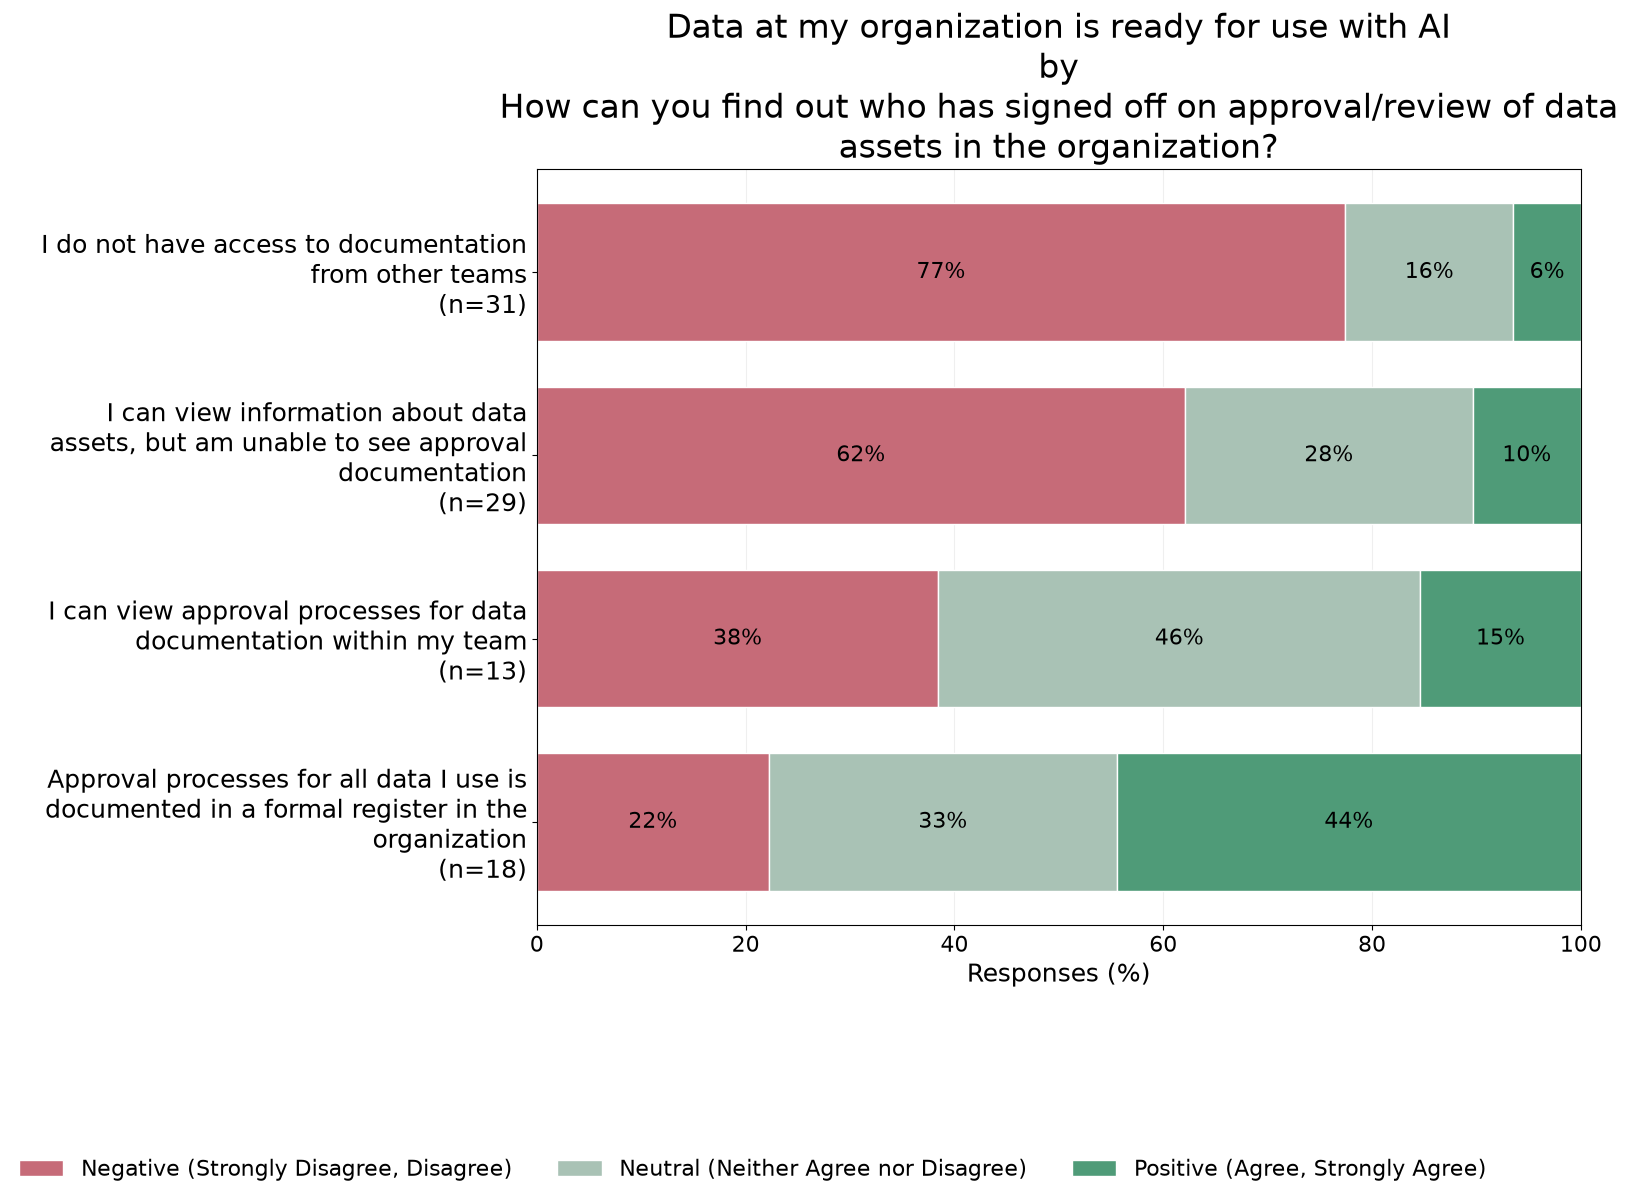

In [5]:
matrices = compute_correlation_matrices(*build_pairwise_data(survey))
top_pairs = top_action_pairs(matrices, survey, "ai_readiness")
display(top_pairs)
for pair in top_pairs.itertuples():
    # plot_action_ai(pair.action, pair.outcome, recoded=False)
    plot_action_ai(pair.action, pair.outcome, recoded=True, include_stats=False)

,action,outcome,rho,p_value
0,actions_endorse_2,self_assess_value,0.452301,0.000004
1,actions_endorse_1,self_assess_value,0.411993,0.000008
2,actions_leadership_2,self_assess_value,0.404121,0.000013


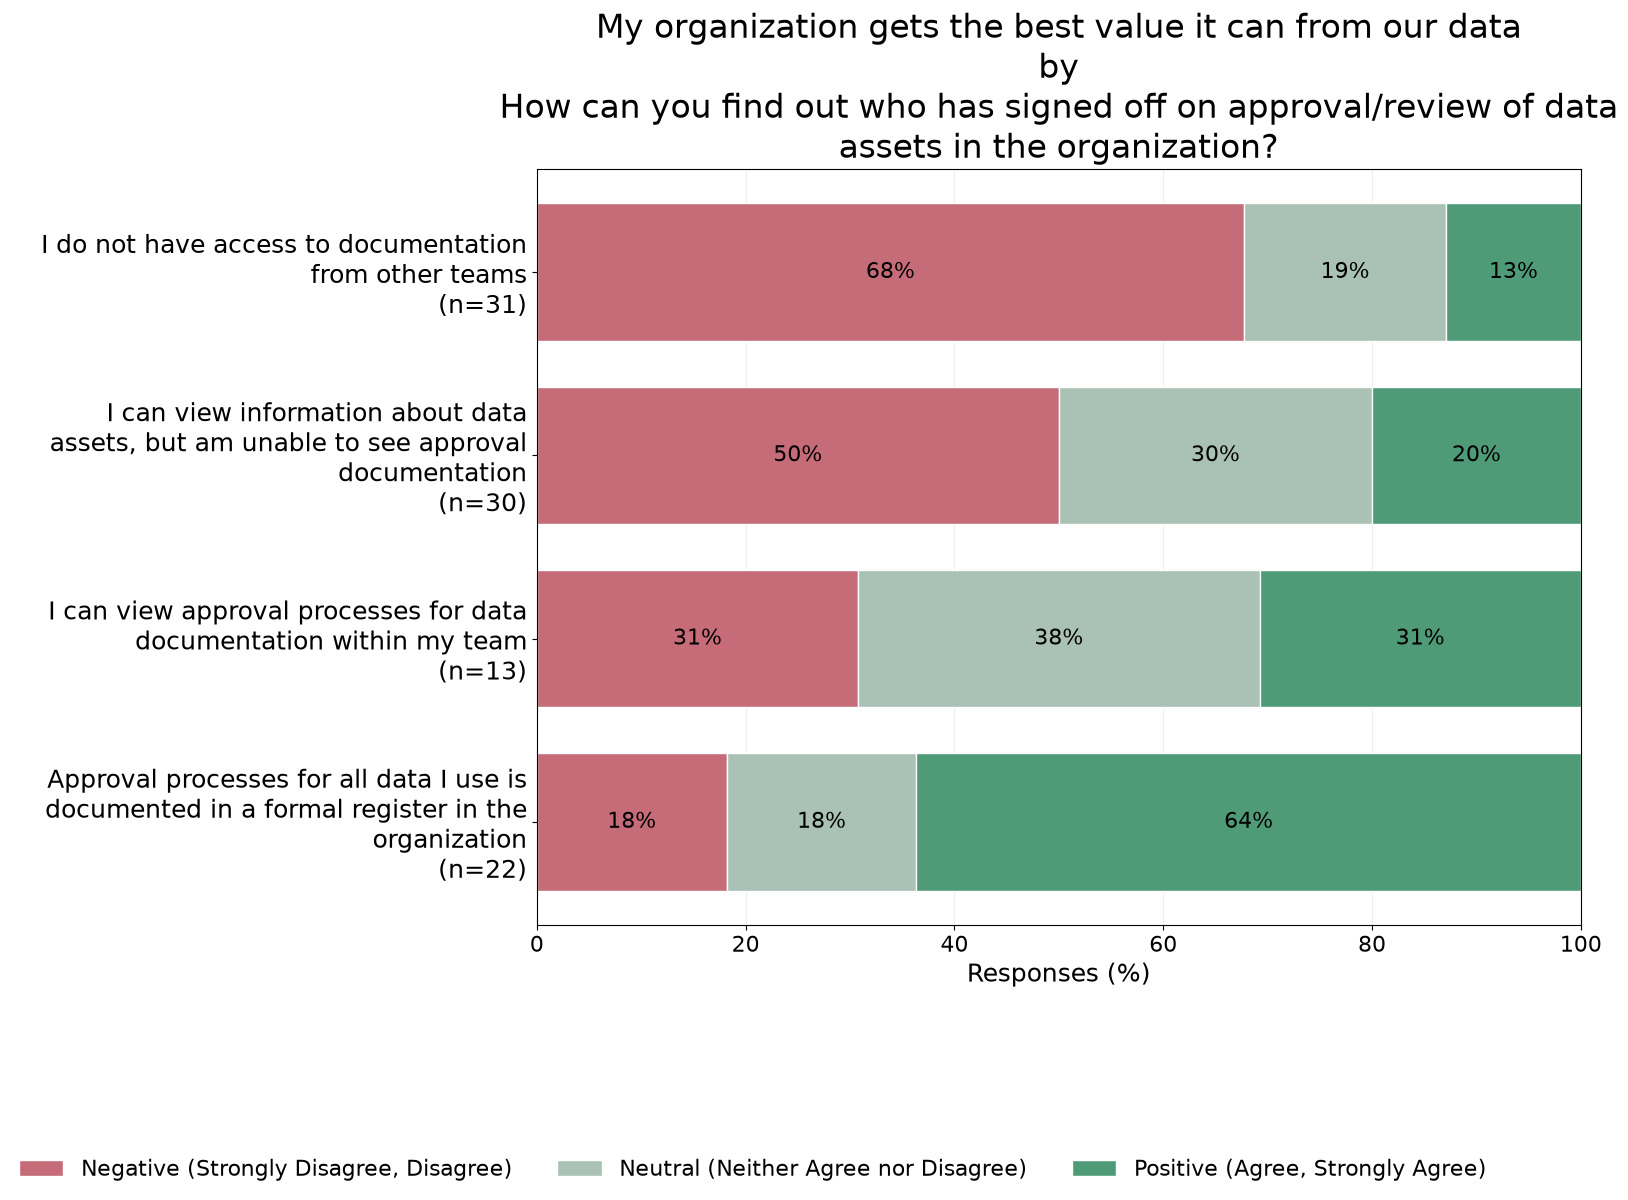

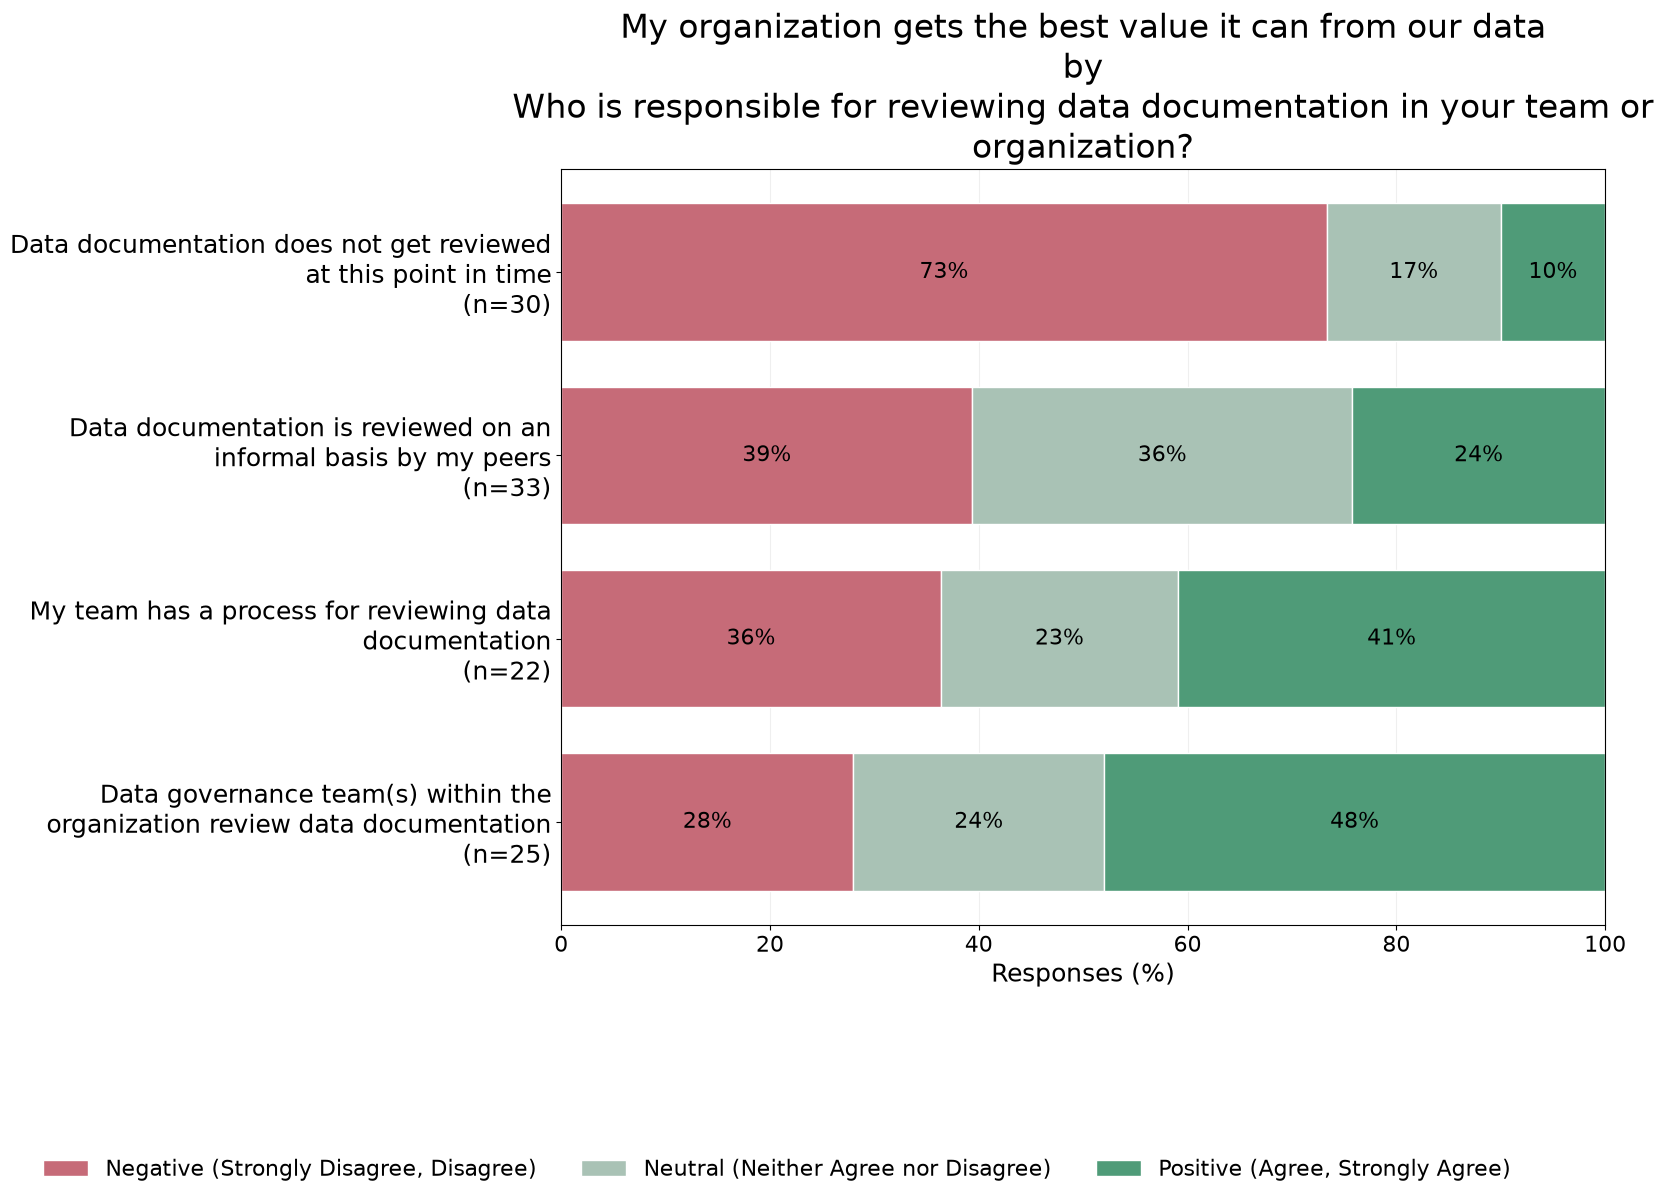

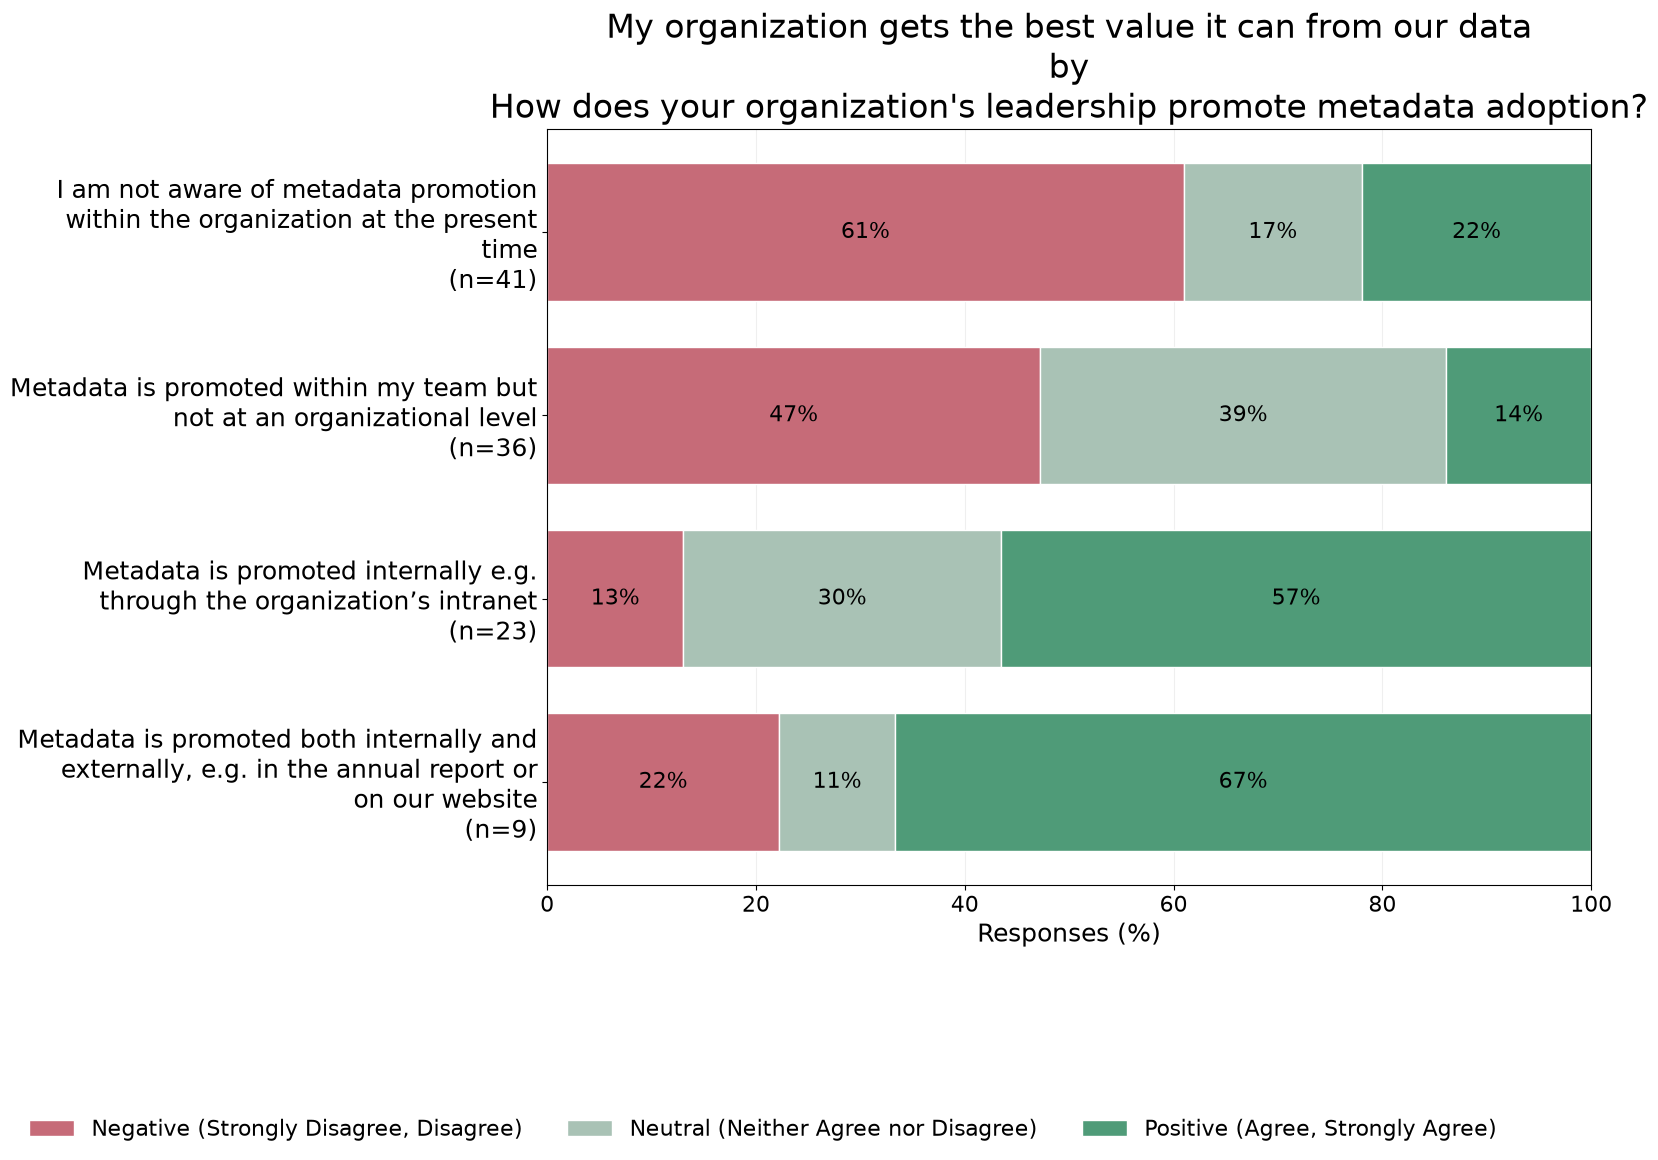

In [6]:
matrices = compute_correlation_matrices(*build_pairwise_data(survey))
top_pairs = top_action_pairs(matrices, survey, "self_assess_value", min_rho=0.3)
display(top_pairs)
for pair in top_pairs.itertuples():
    # plot_action_ai(pair.action, pair.outcome, recoded=False)
    plot_action_ai(pair.action, pair.outcome, recoded=True, include_stats=False)

,action,outcome,rho,p_value
0,actions_leadership_2,self_assess_trust,0.426404,0.000003
1,actions_endorse_2,self_assess_trust,0.416090,0.000025
2,actions_endorse_1,self_assess_trust,0.415398,0.000006


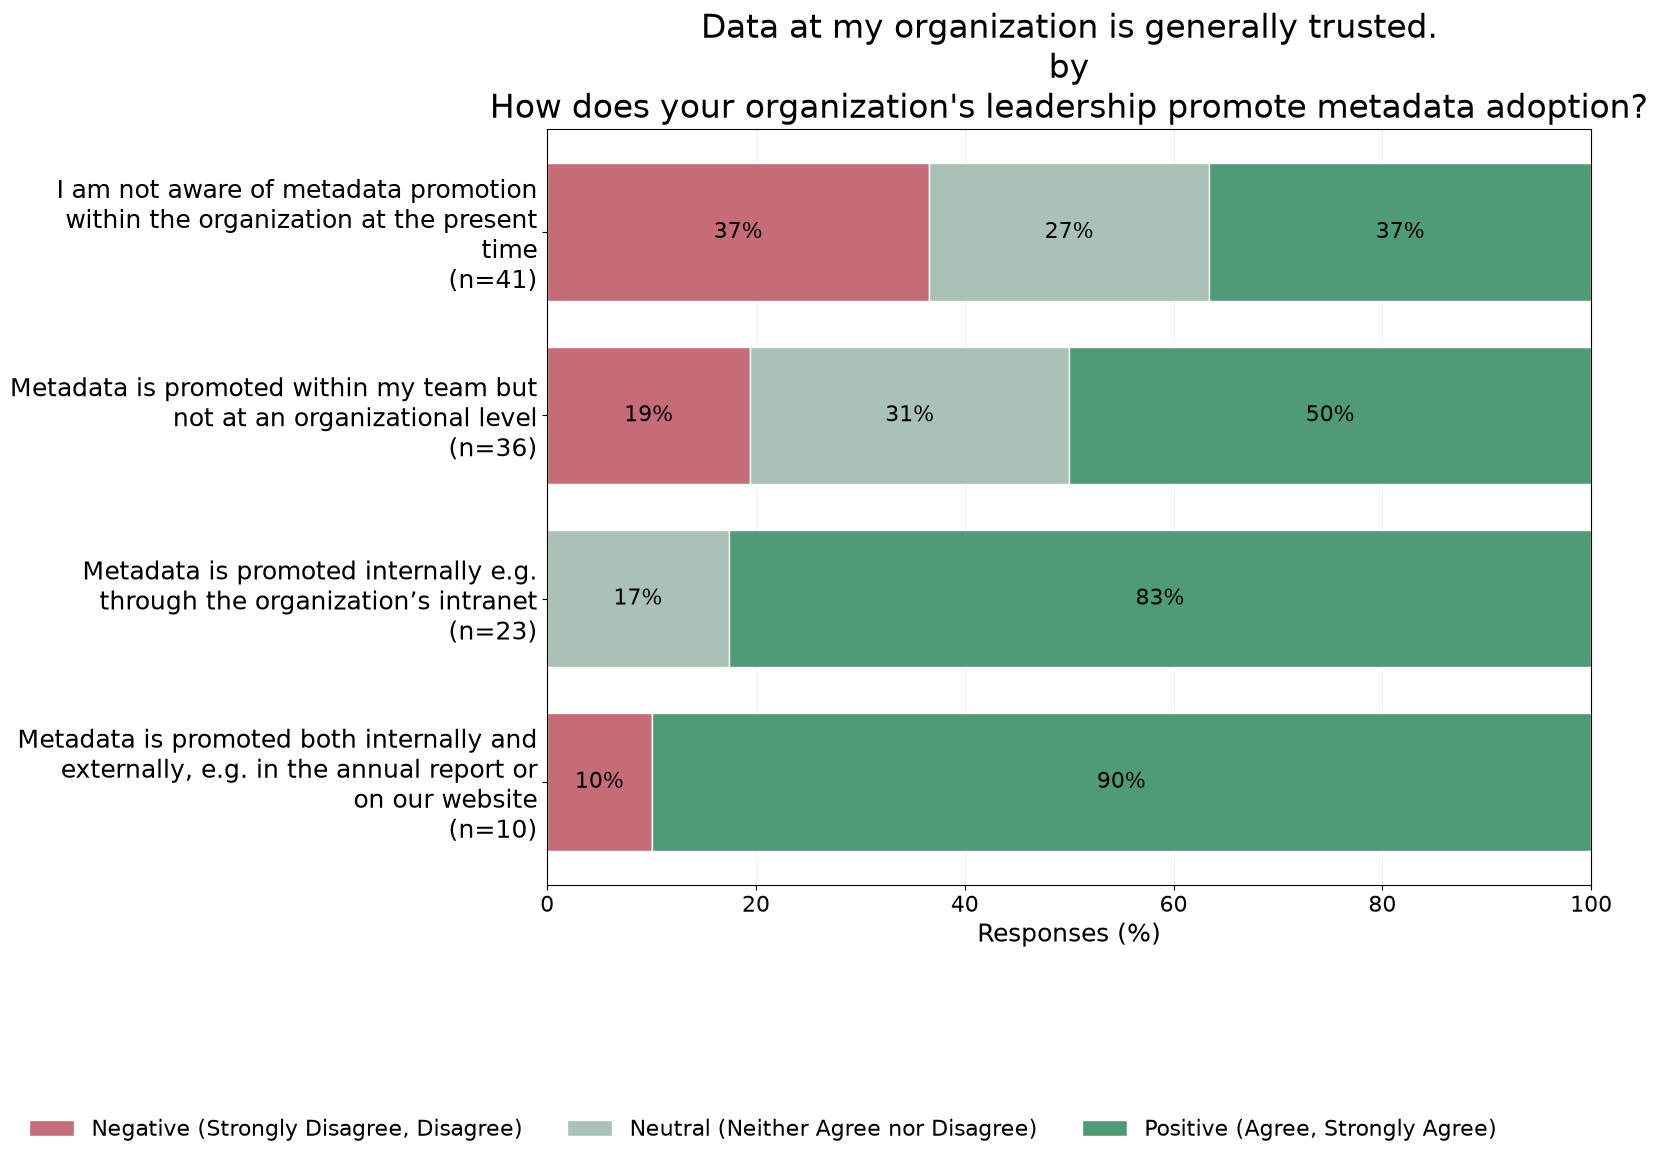

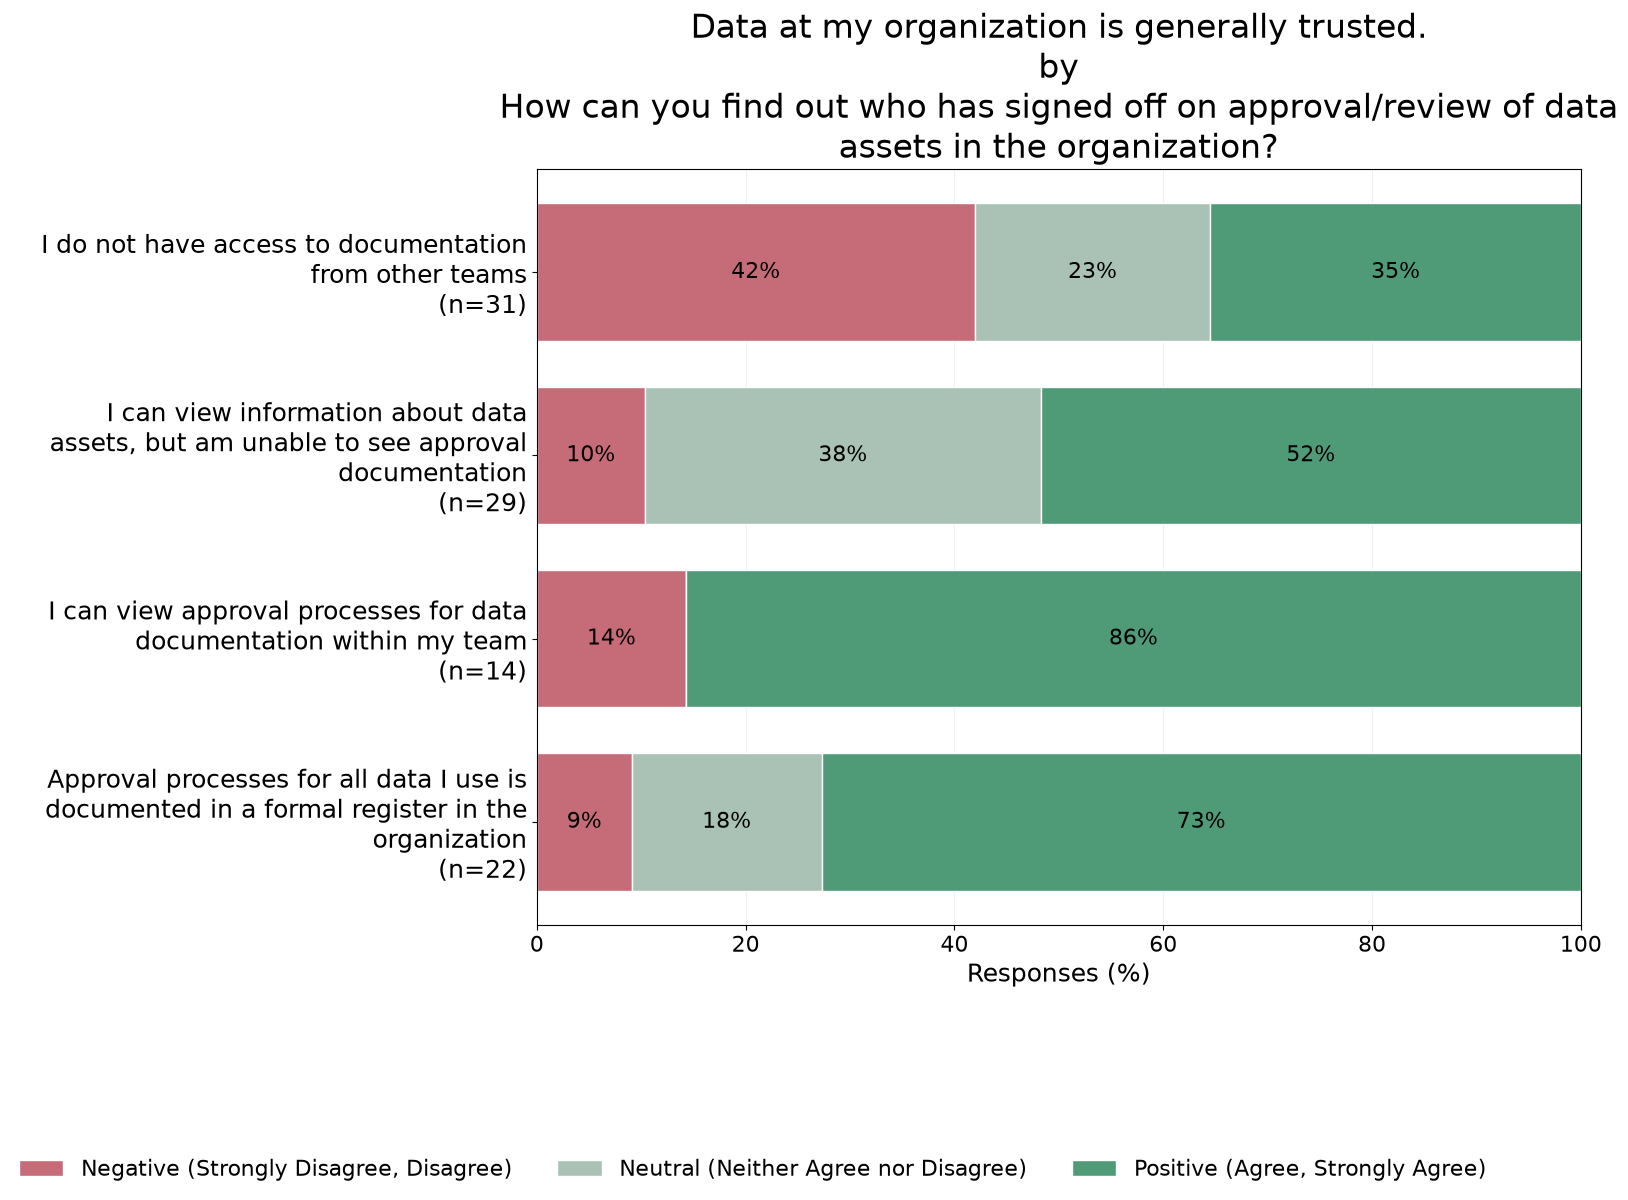

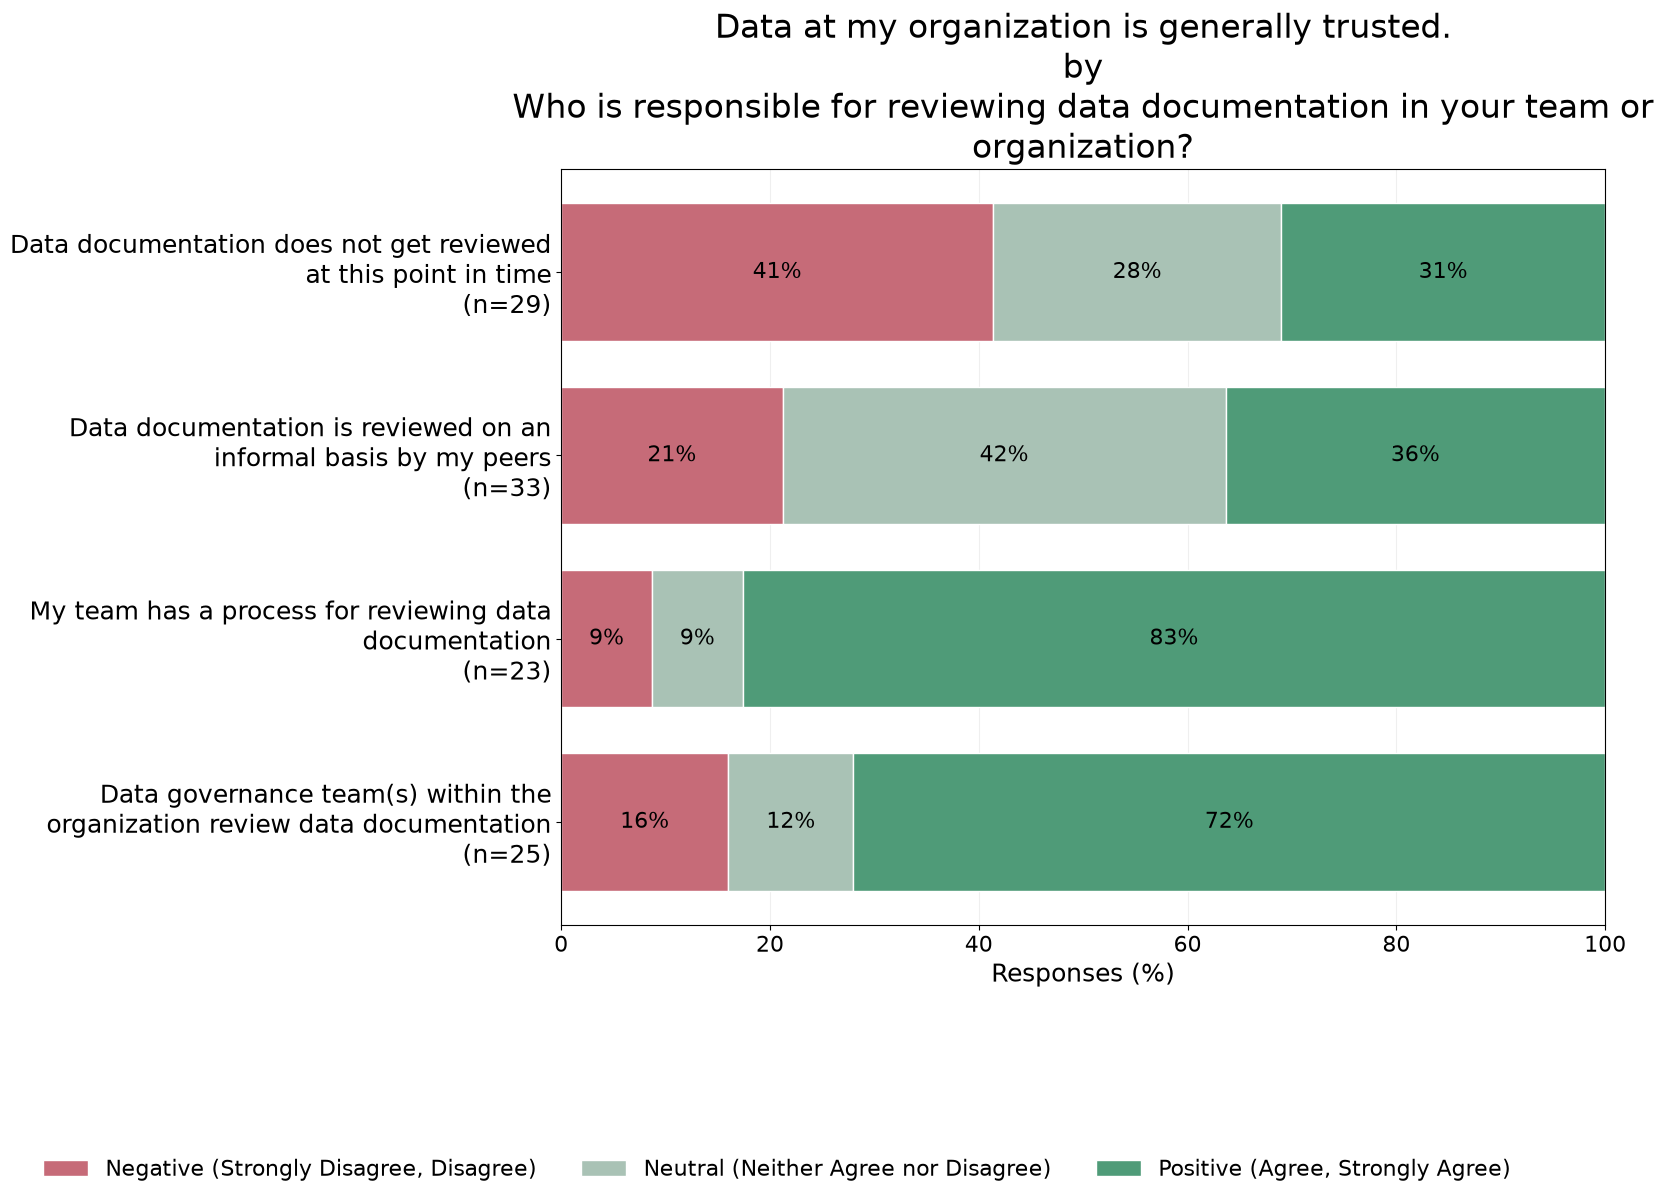

In [7]:
matrices = compute_correlation_matrices(*build_pairwise_data(survey))
top_pairs = top_action_pairs(matrices, survey, "self_assess_trust", min_rho=0.3)
display(top_pairs)
for pair in top_pairs.itertuples():
    # plot_action_ai(pair.action, pair.outcome, recoded=False)
    plot_action_ai(pair.action, pair.outcome, recoded=True, include_stats=False)

,action,outcome,rho,p_value
0,actions_endorse_1,self_assess_secure,0.367869,0.000083
1,actions_inventory_2,self_assess_secure,0.352715,0.000169
2,actions_endorse_2,self_assess_secure,0.325531,0.001286


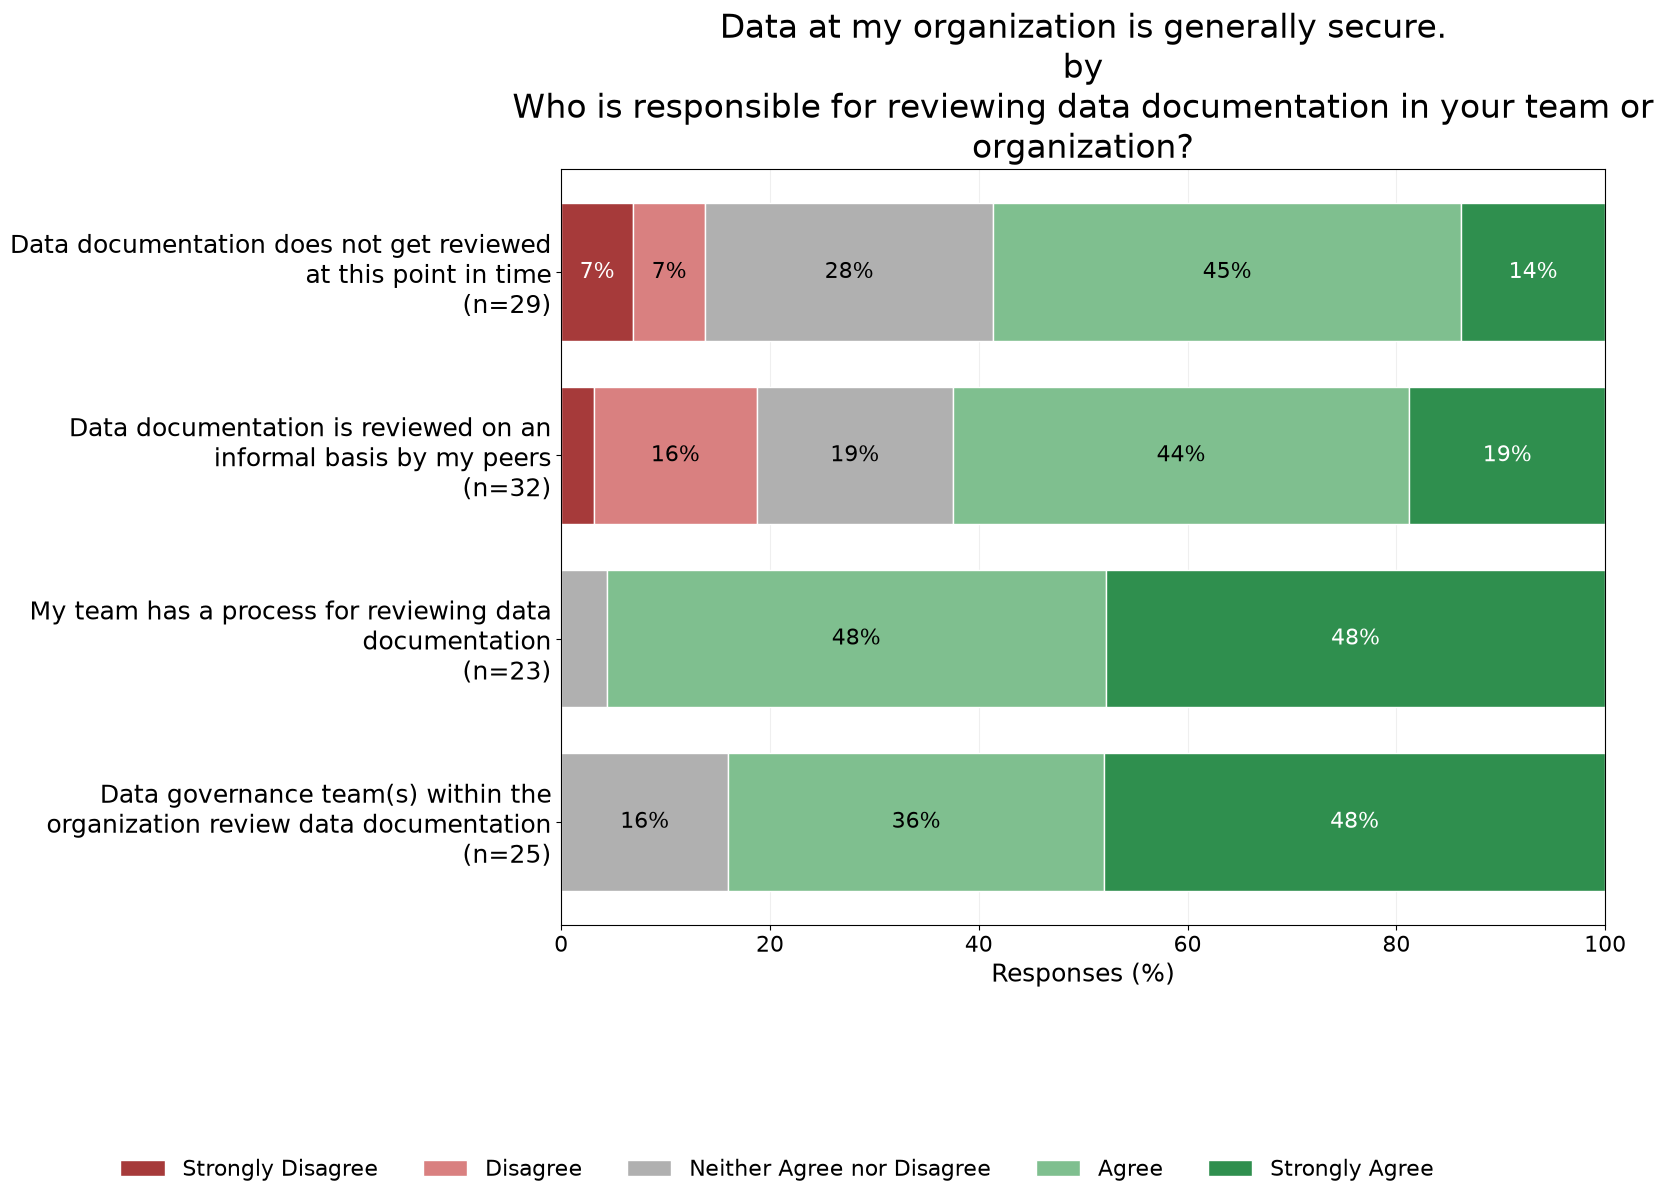

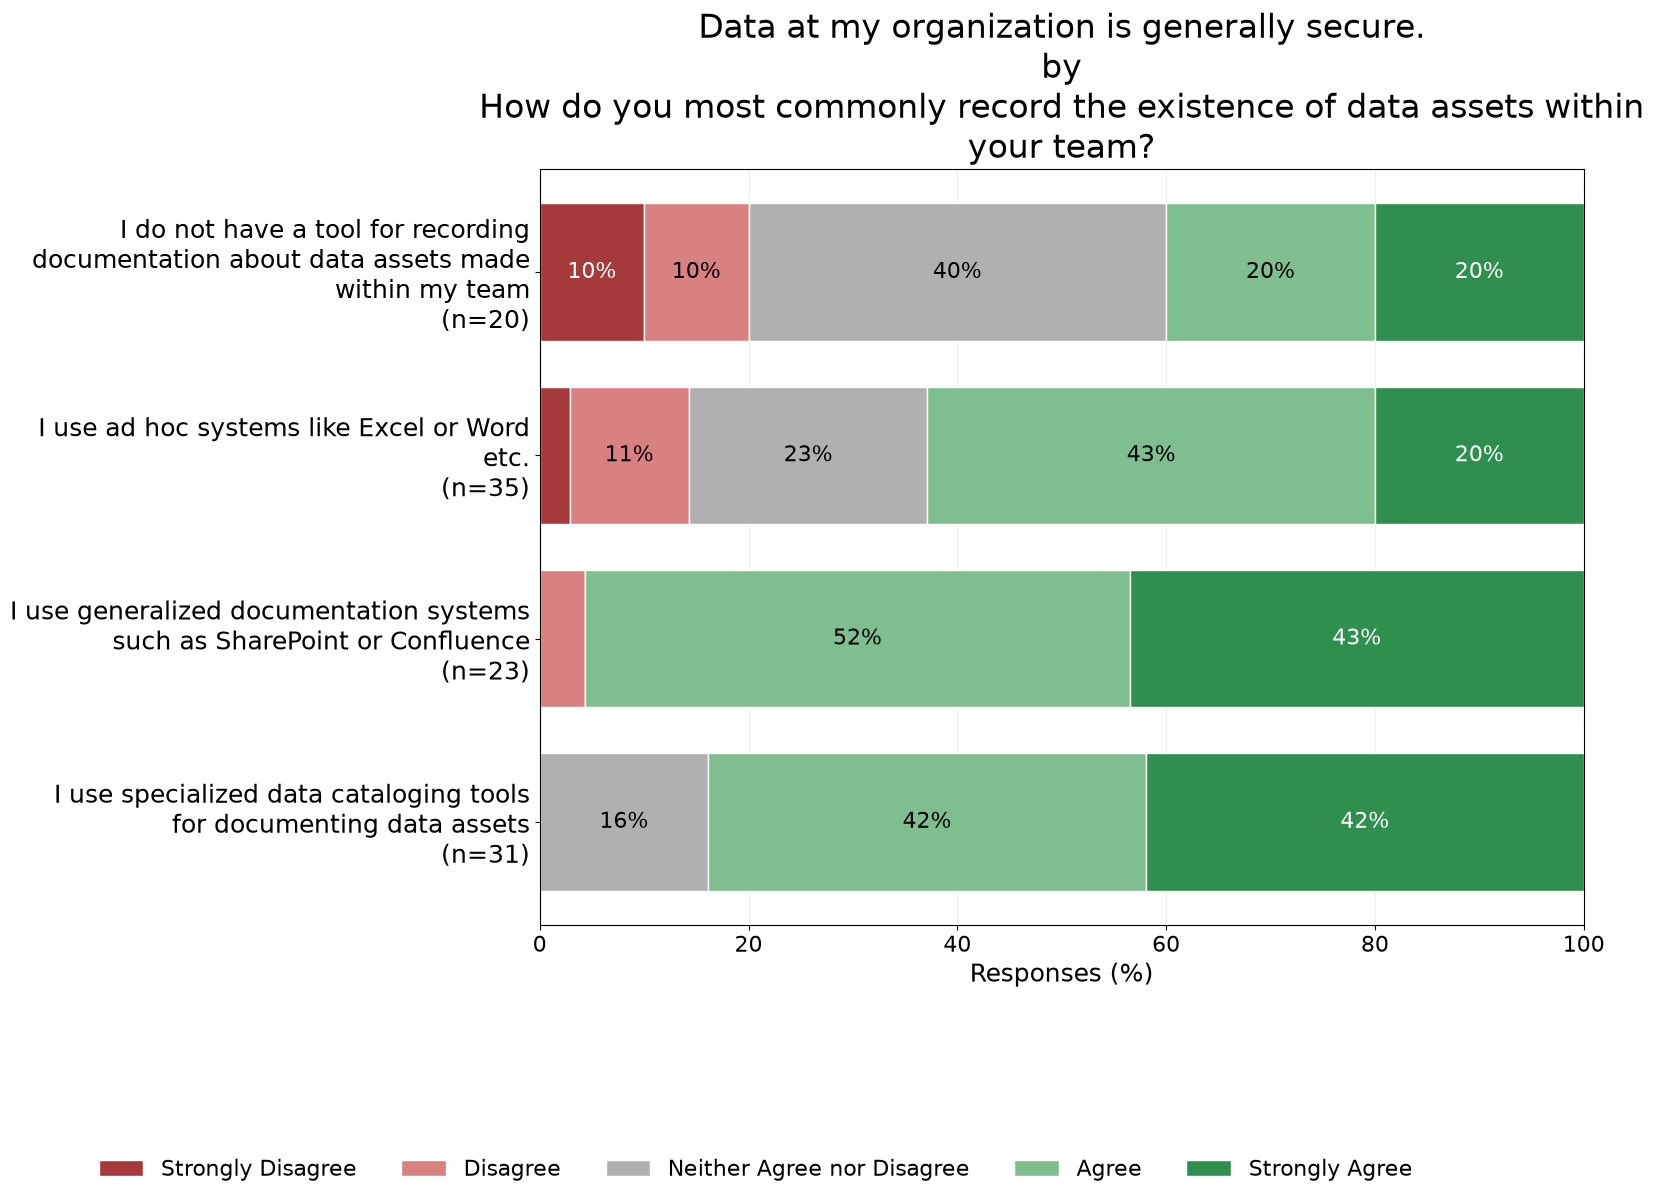

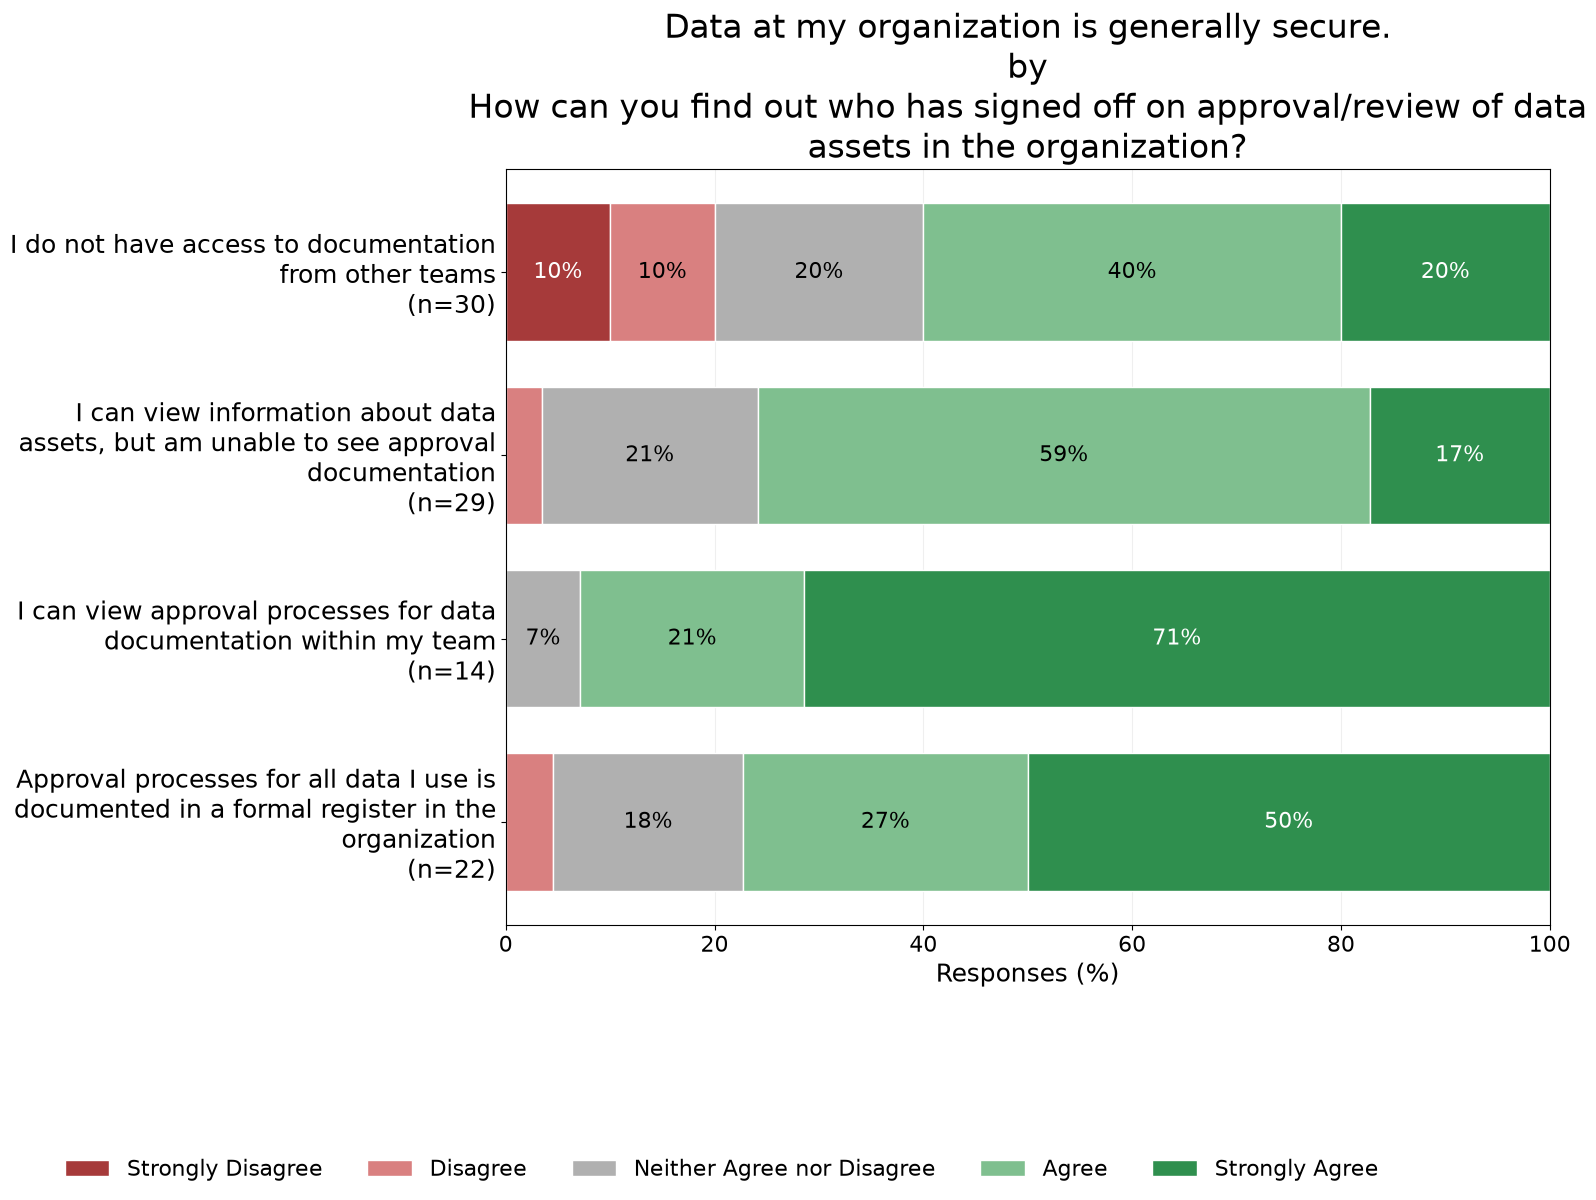

In [8]:
matrices = compute_correlation_matrices(*build_pairwise_data(survey))
top_pairs = top_action_pairs(matrices, survey, "self_assess_secure", min_rho=0.3)
display(top_pairs)
for pair in top_pairs.itertuples():
    # plot_action_ai(pair.action, pair.outcome, recoded=False)
    plot_action_ai(pair.action, pair.outcome, recoded=False, include_stats=False)

## Positive AI outcomes by industry

Grouped bars show the percentage of valid AI-metric responses rated positive (`4` or `5`) within each industry. Industries with fewer than 5 completed responses are combined into `Other`; its rates are pooled from valid metric responses. Missing metric responses are excluded from each metric's denominator. X-axis labels show completed-response totals.

## Positive self-assessment outcomes by industry

Grouped bars show the percentage of valid self-assessment responses rated positive (`4` or `5`) within each industry. As in the AI chart above, industries with fewer than 5 completed responses are combined into `Other`. Missing metric responses are excluded from each metric's denominator.

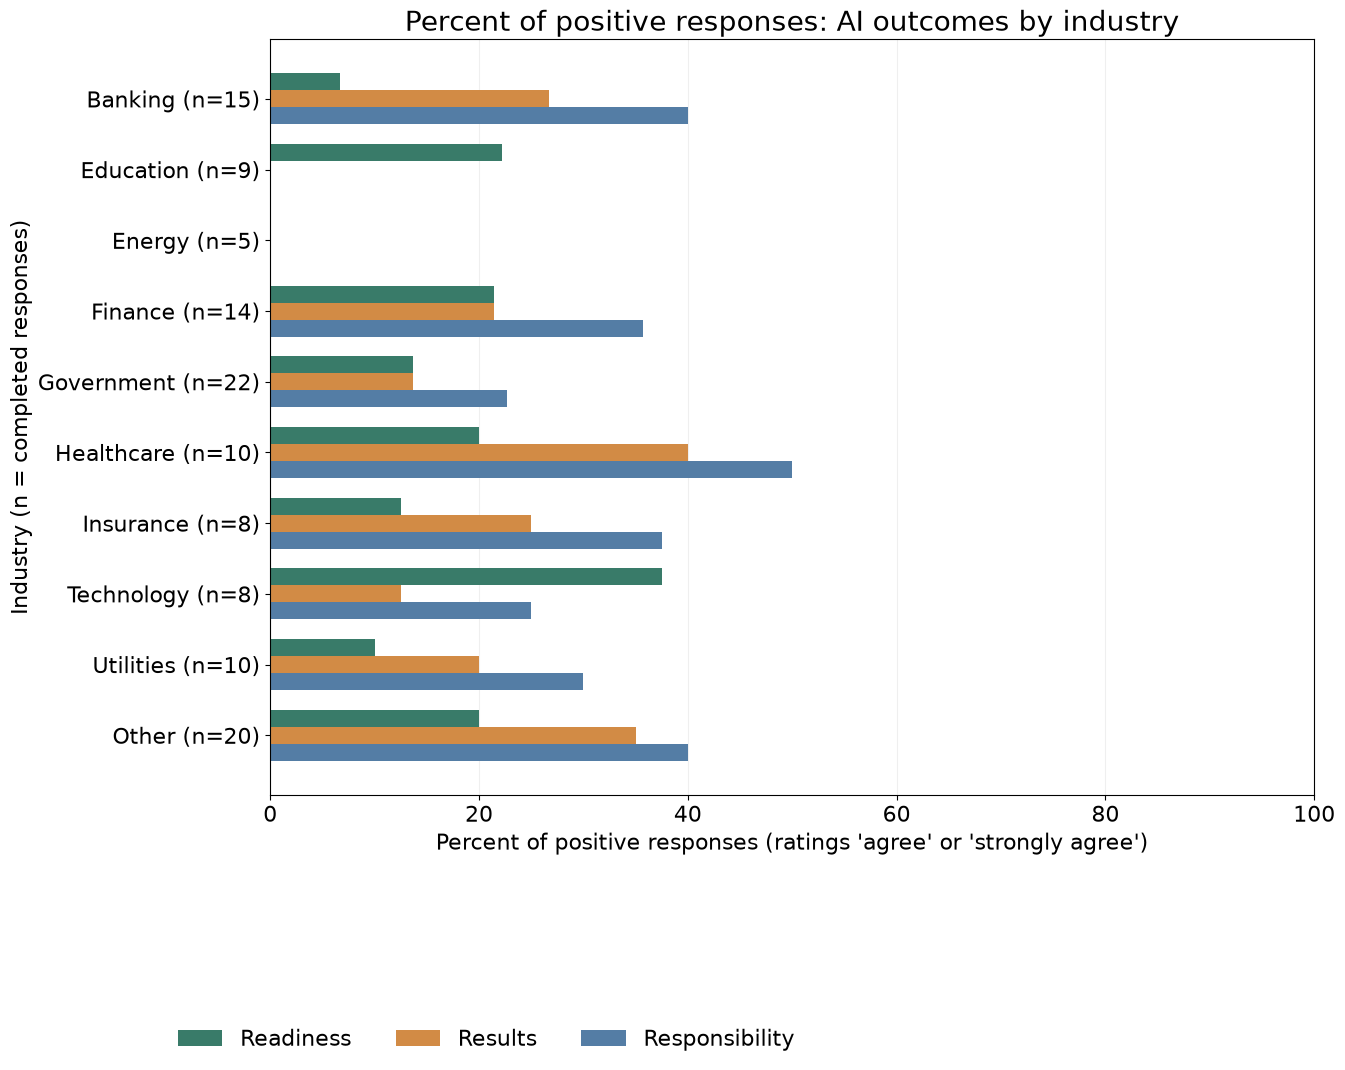

In [9]:
plot_positive_metrics_by_category(
    completed,
    "industry",
    survey.ai_outcome_columns,
    "AI outcomes by industry",
)

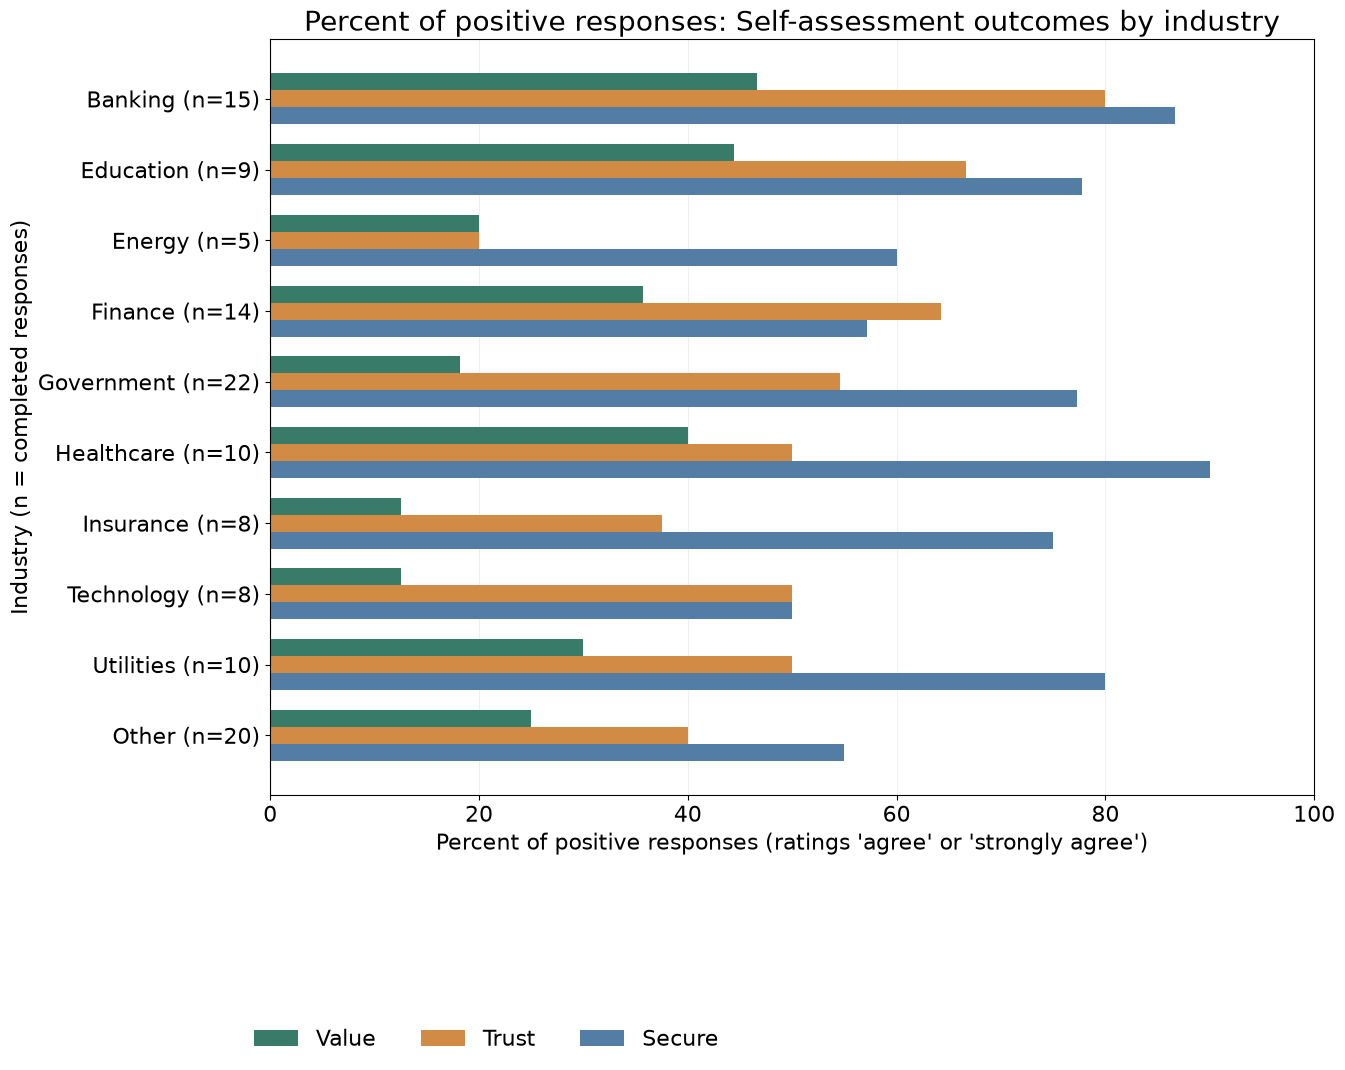

In [10]:
plot_positive_metrics_by_category(
    completed,
    "industry",
    survey.self_assess_columns,
    "Self-assessment outcomes by industry",
)

## Positive AI outcomes by job role

This chart uses the same grouped-bar calculation as the industry charts. Job roles with fewer than 5 completed responses are pooled into `Other`.

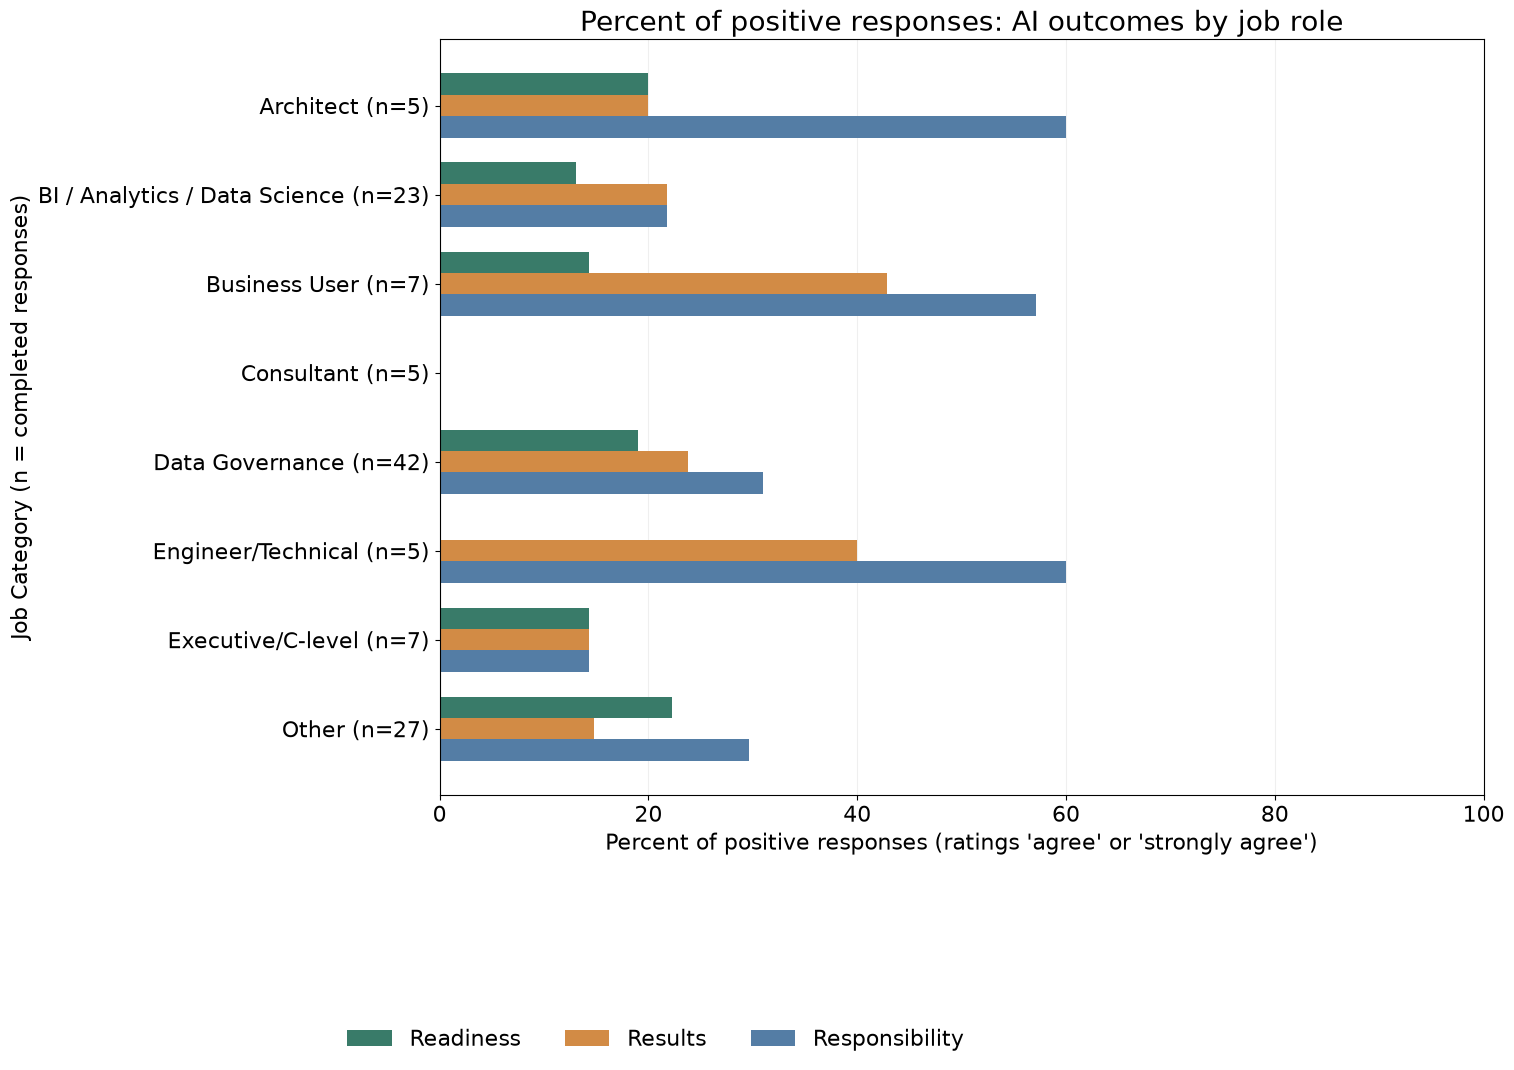

In [11]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    survey.ai_outcome_columns,
    "AI outcomes by job role",
)

## Positive self-assessment outcomes by job role

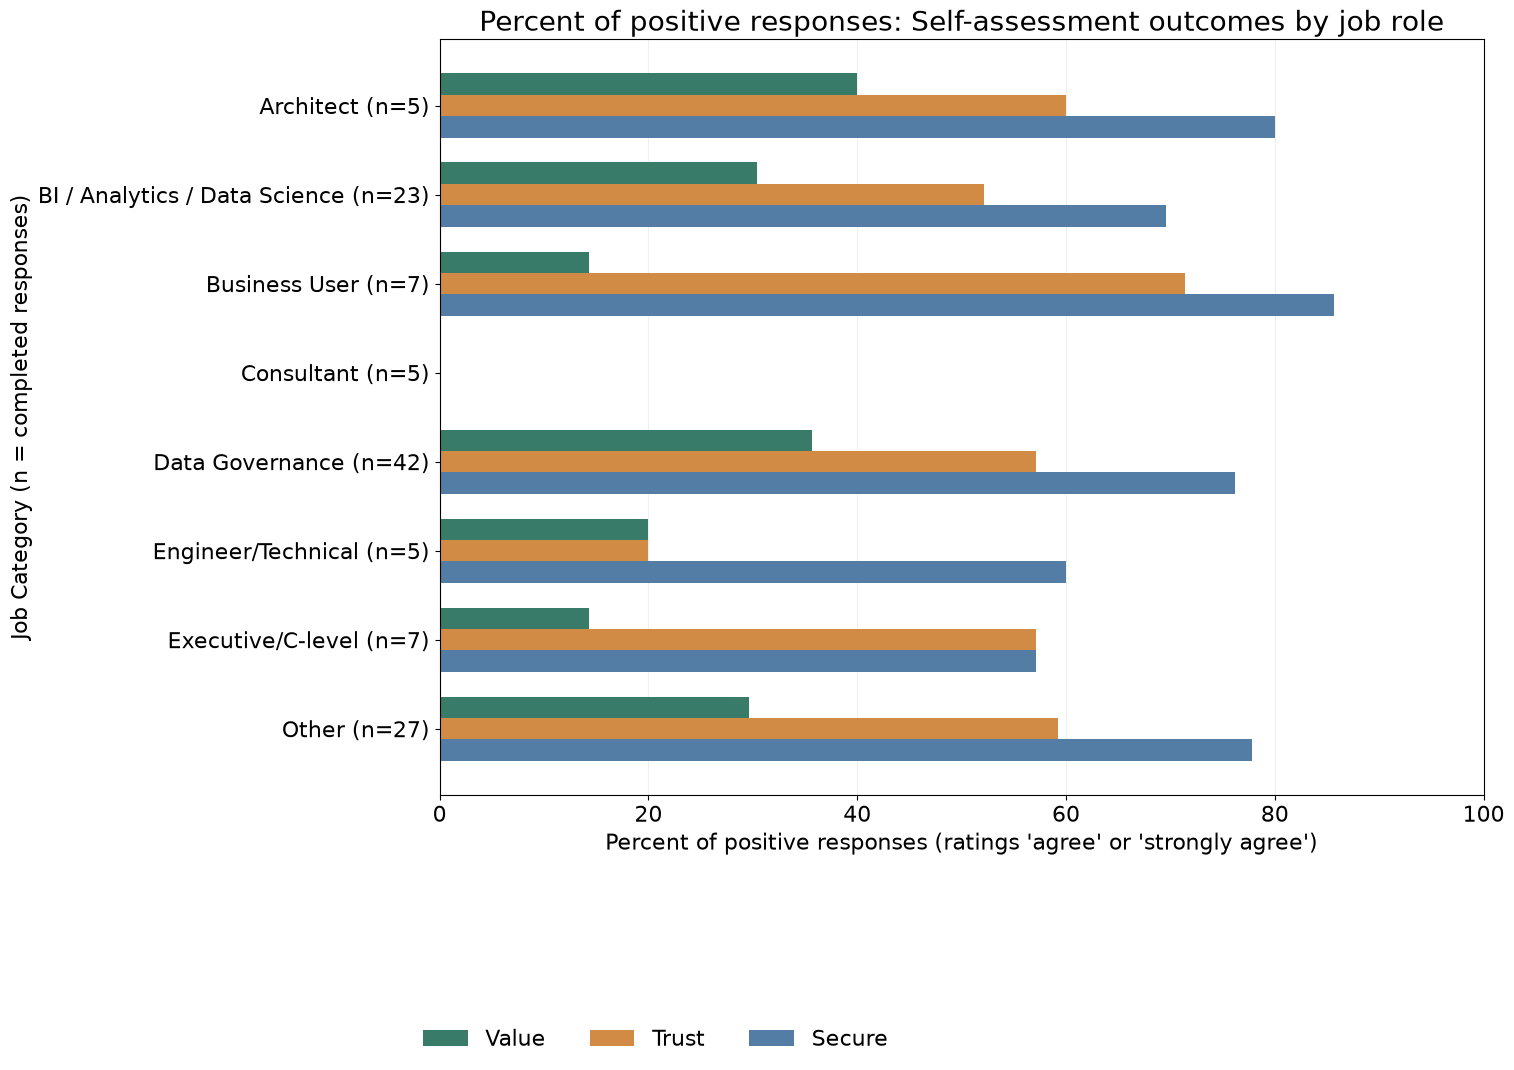

In [12]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    survey.self_assess_columns,
    "Self-assessment outcomes by job role",
)